In [3]:
import pandas as pd
import numpy as np
from cmdstanpy import CmdStanModel
import geopandas as gpd
from libpysal import weights
from sklearn.preprocessing import LabelEncoder
import networkx as nx
from scipy.sparse import diags

In [4]:
df = pd.read_csv("/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/feature_extraction/new_abortion_result.csv")
df

,Unnamed: 0,id,time_window_start,username,Demo_sex_Symbol,Demo_age_Symbol,Demo_ethnicity_Symbol,Demo_highest_educational_qualification_Symbol,Demo_past_vote_vote_choice_in_the_2020_presidential_election_Symbol,Demo_interest_in_politics_Symbol,Demo_marital_status_Symbol,Demo_partisan_loyalties_Symbol,Demo_which_state_of_the_usa_do_they_live_in__Category,Demo_household_income_bracket_Symbol,Belief_opinion_on_the_following_statement_it_should_be_acceptable_for_a_pregnant_woman_to_obtain_a_legal_abortion_if_a_woman_wants_it_for_any_reason_Symbol,state_cleaned
0,40,1542629834953719810,2024-05-19 00:00:00+00:00,Badash1821,s2,a4,e1,q1,vpa2,i4,m1,pid7,ohio,h3,sob4,OH
1,41,1542629834953719810,2024-06-16 00:00:00+00:00,Badash1821,s2,a4,e1,q1,vpa2,i4,m1,pid7,ohio,h3,sob4,OH
2,43,1542629834953719810,2024-07-14 00:00:00+00:00,Badash1821,s2,a4,e1,q1,vpa2,i4,m1,pid7,ohio,h3,sob4,OH
3,44,1542629834953719810,2024-07-28 00:00:00+00:00,Badash1821,s2,a4,e1,q1,vpa3,i4,m2,pid3,ohio,h2,sob1,OH
4,45,1542629834953719810,2024-08-11 00:00:00+00:00,Badash1821,s2,a4,e1,q1,vpa2,i4,m1,pid7,ohio,h3,sob4,OH
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8432,23985,142827500,2024-08-25 00:00:00+00:00,ndrwwwww,s1,a3,e1,q2,vpa3,i4,m2,pid3,illinois,h3,sob1,IL
8433,23986,142827500,2024-09-08 00:00:00+00:00,ndrwwwww,s1,a3,e1,q2,vpa3,i3,m2,pid3,illinois,h4,sob1,IL
8434,23987,142827500,2024-09-22 00:00:00+00:00,ndrwwwww,s1,a3,e1,q2,vpa3,i3,m2,pid4,illinois,h3,sob1,IL
8435,23988,142827500,2024-10-06 00:00:00+00:00,ndrwwwww,s1,a3,e1,q2,vpa1,i3,m2,pid4,illinois,h3,sob1,IL


In [5]:
from sklearn.preprocessing import LabelEncoder

def inspect_encoding(col):
    le = LabelEncoder()
    le.fit(df[col])
    print(f"\n=== Encoding for {col} ===")
    for i, cat in enumerate(le.classes_, start=1):
        print(f"  {i} → {cat}")
    return le

le_sex    = inspect_encoding("Demo_sex_Symbol")
le_age    = inspect_encoding("Demo_age_Symbol")
le_eth    = inspect_encoding("Demo_ethnicity_Symbol")
le_income = inspect_encoding("Demo_household_income_bracket_Symbol")
le_state  = inspect_encoding("state_cleaned")



=== Encoding for Demo_sex_Symbol ===
  1 → s1
  2 → s2

=== Encoding for Demo_age_Symbol ===
  1 → a1
  2 → a2
  3 → a3
  4 → a4
  5 → a5
  6 → a6
  7 → a7

=== Encoding for Demo_ethnicity_Symbol ===
  1 → e1
  2 → e2
  3 → e3
  4 → e4
  5 → e5
  6 → e6

=== Encoding for Demo_household_income_bracket_Symbol ===
  1 → h1
  2 → h2
  3 → h3
  4 → h4
  5 → h5

=== Encoding for state_cleaned ===
  1 → AL
  2 → AR
  3 → AZ
  4 → CA
  5 → CO
  6 → CT
  7 → DC
  8 → DE
  9 → FL
  10 → GA
  11 → HI
  12 → IA
  13 → ID
  14 → IL
  15 → IN
  16 → KS
  17 → KY
  18 → LA
  19 → MA
  20 → MD
  21 → ME
  22 → MI
  23 → MN
  24 → MO
  25 → MS
  26 → MT
  27 → NC
  28 → NE
  29 → NH
  30 → NJ
  31 → NM
  32 → NV
  33 → NY
  34 → OH
  35 → OK
  36 → OR
  37 → PA
  38 → RI
  39 → SC
  40 → SD
  41 → TN
  42 → TX
  43 → UT
  44 → VA
  45 → VT
  46 → WA
  47 → WI
  48 → WY


In [9]:
df

,state_abbreviation,state_simple,state_electoral.college,region,gender,ethnicity,age_bins,college_grad,hh_income,vote2020,...,N_star.96,N_star.97,N_star.98,N_star.99,N_star.100,N_star.101,N_star.102,N_star.103,N_star.104,N_star.median
0,AL,Alabama,Alabama,South,M,Black,6.65+,Does not have a College Degree,"1.[min, 25000)",D,...,148.76728,268.20914,133.47064,194.58831,434.67704,177.02612,323.90333,331.78927,157.18089,176.937630
1,AL,Alabama,Alabama,South,F,White,2.25-34,Has a College Degree,"2.[25000, 50000)",D,...,18.29170,2.14383,48.28856,14.31070,33.71872,41.75969,17.02488,4.46742,58.88781,14.624140
2,AL,Alabama,Alabama,South,M,Hispanic,3.35-44,Does not have a College Degree,"4.[75000, 100000)",D,...,5.73981,13.32785,5.58816,9.84069,10.82239,9.89345,12.25813,2.75835,0.80854,4.732475
3,AL,Alabama,Alabama,South,F,White,4.45-54,Does not have a College Degree,"4.[75000, 100000)",D,...,8.17745,10.19859,17.84635,17.20322,61.42123,14.47678,5.59401,3.83824,35.16691,18.939800
4,AL,Alabama,Alabama,South,F,Black,3.35-44,Does not have a College Degree,"2.[25000, 50000)",D,...,129.69942,43.36045,34.00582,31.65090,13.49886,81.18639,71.35698,22.33110,41.21349,47.086420
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1299523,WY,Wyoming,Wyoming,West,F,Native,1.18-24,Has a College Degree,"2.[25000, 50000)",stay home,...,0.43211,0.15807,0.76154,0.16572,0.41070,0.79644,0.06466,0.18751,1.99962,0.370085
1299524,WY,Wyoming,Wyoming,West,F,Black,1.18-24,Does not have a College Degree,"2.[25000, 50000)",stay home,...,0.24236,0.77892,0.75426,1.05546,0.60422,0.84889,0.68500,0.71477,1.03333,0.706365
1299525,WY,Wyoming,Wyoming,West,M,Mixed-race,6.65+,Has a College Degree,"3.[50000, 75000)",stay home,...,0.17550,0.44190,0.03085,0.60491,0.04941,0.00053,0.00012,0.00971,0.00927,0.009785
1299526,WY,Wyoming,Wyoming,West,F,Asian,6.65+,Has a College Degree,"5.[100000, max]",stay home,...,0.07336,0.68324,0.17583,0.30572,0.14193,0.02940,0.15420,0.04570,0.14782,0.116890


In [6]:

def edges_from_adjacency(W):
    all_edges = []
    n = W.shape[0]
    
    for i in range(n):
        neighbors = np.where(W[i, :] != 0)[0]
        for j in neighbors:
            if i < j:  
                all_edges.append({
                    'node1': i + 1,  
                    'node2': j + 1,
                    'weight': W[i, j]
                })
    
    return pd.DataFrame(all_edges)


def scale_c(C):
    N = C.shape[0]
    
    if hasattr(C, 'toarray'):
        C = C.toarray()
    C = np.asarray(C)
    
    row_sums = C.sum(axis=1).ravel()
    Q = diags(row_sums) - C
    
    Q_dense = Q.toarray() if hasattr(Q, 'toarray') else np.asarray(Q)
    max_diag = np.max(np.diag(Q_dense))
    jitter = max_diag * np.sqrt(np.finfo(float).eps)
    Q_pert = Q_dense + np.diag(np.ones(N) * jitter)
    
    Q_inv = np.linalg.pinv(Q_pert)
    
    variances = np.diag(Q_inv)
    scaling_factor = np.exp(np.mean(np.log(variances)))
    
    return scaling_factor


def prep_icar_data_from_weights(w, N_regions):
    C = np.zeros((N_regions, N_regions))
    for i in range(N_regions):
        for j in w.neighbors[i]:
            C[i, j] = 1

    E = edges_from_adjacency(C)
    
    G = nx.Graph()
    G.add_nodes_from(range(N_regions))
    for _, row in E.iterrows():
        G.add_edge(int(row['node1']) - 1, int(row['node2']) - 1)
    
    components = list(nx.connected_components(G))
    k = len(components)
    
    comp_id = np.zeros(N_regions, dtype=int)
    for idx, component in enumerate(components):
        for node in component:
            comp_id[int(node)] = idx
    
    group_size = np.array([len(comp) for comp in components])
    
    group_idx = comp_id + 1
    
    scale_factor = scale_c(C)
    inv_sqrt_scale_factor = np.ones(k) / np.sqrt(scale_factor)
    
    m = np.sum(group_size > 1) - 1
    
    if m > 0:
        main_comp = None
        for i, size in enumerate(group_size):
            if size > 1:
                main_comp = i
                break
        
        comp_id_adjusted = comp_id.copy()
        for i in range(k):
            if group_size[i] == 1:
                comp_id_adjusted[comp_id == i] = main_comp
        
        unique_comps = np.unique(comp_id_adjusted)
        unique_comps = unique_comps[unique_comps != main_comp]
        
        A = np.zeros((N_regions, m))
        for idx, comp in enumerate(unique_comps):
            A[comp_id_adjusted == comp, int(idx)] = 1
    else:
        A = np.zeros((N_regions, 0))
    
    return {
        'k': int(k),
        'group_size': group_size.tolist(),
        'N_edges': len(E),
        'node1': E['node1'].values.tolist(),
        'node2': E['node2'].values.tolist(),
        'group_idx': group_idx.tolist(),
        'm': int(m),
        'A': A.tolist(),
        'inv_sqrt_scale_factor': inv_sqrt_scale_factor.tolist(),
    }


def moran_coefficient(x, W, warn=True):
    row_sums = W.sum(axis=1)
    zero_idx = np.where(row_sums == 0)[0]
    
    if len(zero_idx) > 0:
        if warn:
            print(f"{len(zero_idx)} observations with no neighbors. Dropping from calculation.")
        keep_idx = row_sums > 0
        x = x[keep_idx]
        W = W[np.ix_(keep_idx, keep_idx)]
    
    n = len(x)
    xbar = np.mean(x)
    z = x - xbar
    z_tilde = W @ z
    A = np.sum(W)
    mc = (n / A) * (z @ z_tilde) / (z @ z)
    
    return np.round(mc, 3)


df = pd.read_csv("/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/feature_extraction/new_abortion_result.csv")

likert_order = ["sob1", "sob2", "sob3", "sob4"]
df["y_cat"] = pd.Categorical(
    df["Belief_opinion_on_the_following_statement_it_should_be_acceptable_for_a_pregnant_woman_to_obtain_a_legal_abortion_if_a_woman_wants_it_for_any_reason_Symbol"],
    categories=likert_order, ordered=True
)
df["y"] = df["y_cat"].cat.codes + 1
K = len(likert_order)

# Encode categorical predictors
def encode_var(col):
    le = LabelEncoder()
    encoded = le.fit_transform(df[col]) + 1
    n_cats = len(le.classes_)
    print(f"{col}: {n_cats} categories")
    return encoded, n_cats

df["sex_idx"], J_sex = encode_var("Demo_sex_Symbol")
df["age_idx"], J_age = encode_var("Demo_age_Symbol")
df["eth_idx"], J_eth = encode_var("Demo_ethnicity_Symbol")
df["income_idx"], J_income = encode_var("Demo_household_income_bracket_Symbol")
df["state_idx"], N_regions = encode_var("state_cleaned")

print(f"\nTotal observations: {len(df)}")
print(f"Number of states: {N_regions}")


# Build spatial structure
shp = gpd.read_file("/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/tl_2025_us_state/tl_2025_us_state.shp")
shp["STATE"] = shp["STUSPS"].str.upper()

states_in_data = df["state_cleaned"].str.upper().unique()
shp = shp[shp["STATE"].isin(states_in_data)]

state_order = sorted(df["state_cleaned"].unique())
shp = shp.set_index("STATE").loc[[s.upper() for s in state_order]].reset_index()

print(f"Shapefile regions: {len(shp)}")

w = weights.Queen.from_dataframe(shp)

icar_data = prep_icar_data_from_weights(w, N_regions)

print(f"\nICAR structure:")
print(f"  Connected components: {icar_data['k']}")
print(f"  Component sizes: {icar_data['group_size']}")
print(f"  Number of edges: {icar_data['N_edges']}")
print(f"  Extra intercepts (m): {icar_data['m']}")
print(f"  Scaling factors: {icar_data['inv_sqrt_scale_factor']}")

# Check spatial autocorrelation in outcome
C = np.zeros((N_regions, N_regions))
for i in range(N_regions):
    for j in w.neighbors[i]:
        C[i, j] = 1

# Aggregate outcome by state for Moran's I
state_means = df.groupby("state_idx")["y"].mean().values
mc_val = moran_coefficient(state_means, C)
print(f"\nMoran's I for state-level outcome: {mc_val}")

# Stan data
stan_data = {
    "N": len(df),
    "K": K,
    "y": df["y"].astype(int).tolist(),
    
    # Predictor dimensions
    "J_sex": J_sex,
    "J_age": J_age,
    "J_eth": J_eth,
    "J_income": J_income,
    "N_regions": N_regions,
    
    # Predictor indices
    "sex_idx": df["sex_idx"].astype(int).tolist(),
    "age_idx": df["age_idx"].astype(int).tolist(),
    "eth_idx": df["eth_idx"].astype(int).tolist(),
    "income_idx": df["income_idx"].astype(int).tolist(),
    "state_idx": df["state_idx"].astype(int).tolist(),
    
    # ICAR spatial structure
    **icar_data
}

print(f"\nStan data prepared with {len(stan_data)} components")


Demo_sex_Symbol: 2 categories
Demo_age_Symbol: 7 categories
Demo_ethnicity_Symbol: 6 categories
Demo_household_income_bracket_Symbol: 5 categories
state_cleaned: 48 categories

Total observations: 8437
Number of states: 48
Shapefile regions: 48


/tmp/ipykernel_1629/980485028.py:166: FutureWarning: `use_index` defaults to False but will default to True in future. Set True/False directly to control this behavior and silence this warning
  w = weights.Queen.from_dataframe(shp)



ICAR structure:
  Connected components: 2
  Component sizes: [47, 1]
  Number of edges: 104
  Extra intercepts (m): 0
  Scaling factors: [0.002273974148637233, 0.002273974148637233]
1 observations with no neighbors. Dropping from calculation.

Moran's I for state-level outcome: 0.113

Stan data prepared with 22 components


/home/yuyue/stan_env/lib/python3.12/site-packages/libpysal/weights/contiguity.py:347: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
 There is 1 island with id: 10.
  W.__init__(self, neighbors, ids=ids, **kw)


In [10]:

fit.save_csvfiles(dir="/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/new_stan_output/mrp_results/")

summary_df = fit.summary()

summary_df.to_csv("/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/new_stan_output/mrp_summary.csv", index=True)

posterior_draws = fit.draws_pd()  

posterior_draws.to_csv("/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/new_stan_output/mrp_draws.csv", index=False)

In [ ]:
# Stan code
stan_code = '''
functions {
  real icar_normal_lpdf(vector phi, int N_edges,
                        array[] int node1, array[] int node2) {
    return -0.5 * dot_self(phi[node1] - phi[node2]);
  }
}

data {
  int<lower=1> N;                   
  int<lower=2> K;                  
  array[N] int<lower=1, upper=K> y;

  int<lower=1> J_sex;
  int<lower=1> J_age;
  int<lower=1> J_eth;
  int<lower=1> J_income;
  int<lower=1> N_regions;

  array[N] int<lower=1, upper=J_sex> sex_idx;
  array[N] int<lower=1, upper=J_age> age_idx;
  array[N] int<lower=1, upper=J_eth> eth_idx;
  array[N] int<lower=1, upper=J_income> income_idx;
  array[N] int<lower=1, upper=N_regions> state_idx;

  // ICAR structure
  int<lower=1> N_edges;
  array[N_edges] int node1;
  array[N_edges] int node2;

  int<lower=1> k;                           // number of connected components
  array[k] int group_size;                  // size of each connected component
  array[N_regions] int group_idx;           // component assignment for each region
  vector[k] inv_sqrt_scale_factor;          // ICAR variance scale adjustment
  
  // For handling disconnected components
  int<lower=0> m;                           // number of extra intercepts needed
  matrix[N_regions, m] A;                   // constraint matrix for multiple components
}

parameters {
  real alpha;
  ordered[K-1] kappa;

  vector[J_sex-1] eta_sex_tilde;
  vector[J_age-1] eta_age_raw;             
  vector[J_eth-1] eta_eth_tilde;
  vector[J_income-1] eta_income_raw;      
  vector[N_regions] eta_state_raw;

  real<lower=0> sigma_sex;
  real<lower=0> sigma_age;
  real<lower=0> sigma_eth;
  real<lower=0> sigma_income;
  real<lower=0> sigma_state;
  
  vector[m] alpha_component;                // Extra intercepts for disconnected components
}

transformed parameters {
  vector[J_sex] eta_sex;
  vector[J_age] eta_age;
  vector[J_eth] eta_eth;
  vector[J_income] eta_income;
  vector[N_regions] eta_state;

  // Hard sum-to-zero constraints for sex and ethnicity
  for (i in 1:(J_sex-1)) eta_sex[i] = sigma_sex * eta_sex_tilde[i];
  eta_sex[J_sex] = -sum(eta_sex[1:(J_sex-1)]);

  for (i in 1:(J_eth-1)) eta_eth[i] = sigma_eth * eta_eth_tilde[i];
  eta_eth[J_eth] = -sum(eta_eth[1:(J_eth-1)]);

  // Random walk with hard sum-to-zero for age
  eta_age[1] = sigma_age * eta_age_raw[1];
  for (i in 2:(J_age-1)) {
    eta_age[i] = eta_age[i-1] + sigma_age * eta_age_raw[i];
  }
  // Last category forced to sum to zero
  eta_age[J_age] = -sum(eta_age[1:(J_age-1)]);

  // Random walk with hard sum-to-zero for income
  eta_income[1] = sigma_income * eta_income_raw[1];
  for (i in 2:(J_income-1)) {
    eta_income[i] = eta_income[i-1] + sigma_income * eta_income_raw[i];
  }
  eta_income[J_income] = -sum(eta_income[1:(J_income-1)]);

  // ICAR spatial effects with proper scaling
  for (i in 1:N_regions) {
    int component = group_idx[i];
    eta_state[i] = sigma_state * inv_sqrt_scale_factor[component] * eta_state_raw[i];
  }
  
  // allows disconnected geographic regions to have different baseline levels
  if (m > 0) {
    eta_state = eta_state + A * alpha_component;
  }
}

model {
  // Priors
  alpha ~ normal(0, 2);
  kappa ~ normal(0, 3);

  // Sum-to-zero effects
  eta_sex_tilde ~ normal(0, 1);
  eta_eth_tilde ~ normal(0, 1);
  
  // Random walk priors 
  eta_age_raw ~ normal(0, 1);
  eta_income_raw ~ normal(0, 1);
  
  sigma_sex ~ normal(0, 1);
  sigma_age ~ normal(0, 1);
  sigma_eth ~ normal(0, 1);
  sigma_income ~ normal(0, 1);
  sigma_state ~ normal(0, 1);

  // ICAR prior on raw spatial effects
  target += icar_normal_lpdf(eta_state_raw | N_edges, node1, node2);
  
  // Sum-to-zero constraint per connected component
  for (j in 1:k) {
    real component_sum = 0;
    for (i in 1:N_regions) {
      if (group_idx[i] == j) {
        component_sum += eta_state_raw[i];
      }
    }
    target += normal_lpdf(component_sum | 0, 0.001 * group_size[j]);
  }
  
  // Prior on component intercepts
  if (m > 0) {
    alpha_component ~ normal(0, 1);
  }

  // Ordered logistic
  for (i in 1:N) {
    real mu = alpha
              + eta_sex[sex_idx[i]]
              + eta_age[age_idx[i]]
              + eta_eth[eth_idx[i]]
              + eta_income[income_idx[i]]
              + eta_state[state_idx[i]];
    y[i] ~ ordered_logistic(mu, kappa);
  }
}

generated quantities {
  vector[N] mu;
  vector[N] log_lik;
  
  for (i in 1:N) {
    mu[i] = alpha
            + eta_sex[sex_idx[i]]
            + eta_age[age_idx[i]]
            + eta_eth[eth_idx[i]]
            + eta_income[income_idx[i]]
            + eta_state[state_idx[i]];
    log_lik[i] = ordered_logistic_lpmf(y[i] | mu[i], kappa);
  }
}
'''


# Compile and Sample

with open('mrp.stan', 'w') as f:
    f.write(stan_code)

model = CmdStanModel(stan_file='mrp.stan')

fit = model.sample(
    data=stan_data,
    chains=8,
    parallel_chains=8,
    iter_warmup=2000,
    iter_sampling=1000,
    adapt_delta=0.995,
    max_treedepth=13,
    show_console=True
)

print(fit.summary())


00:42:58 - cmdstanpy - INFO - compiling stan file /tmp/tmp2nrbi678/tmpimi_86km.stan to exe file /mnt/c/Users/yuyue/AppData/Local/Programs/Microsoft VS Code/mrp
00:43:10 - cmdstanpy - INFO - compiled model executable: /mnt/c/Users/yuyue/AppData/Local/Programs/Microsoft VS Code/mrp
00:43:10 - cmdstanpy - INFO - Chain [1] start processing
00:43:10 - cmdstanpy - INFO - Chain [2] start processing
00:43:10 - cmdstanpy - INFO - Chain [3] start processing
00:43:10 - cmdstanpy - INFO - Chain [4] start processing
00:43:10 - cmdstanpy - INFO - Chain [5] start processing
00:43:10 - cmdstanpy - INFO - Chain [6] start processing
00:43:10 - cmdstanpy - INFO - Chain [7] start processing
00:43:10 - cmdstanpy - INFO - Chain [8] start processing


Chain [5] method = sample (Default)Chain [7] method = sample (Default)
Chain [7] sample
Chain [7] num_samples = 1000 (Default)
Chain [7] num_warmup = 2000
Chain [7] save_warmup = false (Default)
Chain [7] thin = 1 (Default)
Chain [7] adapt
Chain [7] engaged = true (Default)
Chain [8] method = sample (Default)
Chain [8] sample
Chain [8] num_samples = 1000 (Default)
Chain [8] num_warmup = 2000
Chain [8] save_warmup = false (Default)
Chain [8] thin = 1 (Default)

Chain [5] sample
Chain [5] num_samples = 1000 (Default)
Chain [5] num_warmup = 2000
Chain [5] save_warmup = false (Default)
Chain [5] thin = 1 (Default)
Chain [5] adapt
Chain [2] method = sample (Default)
Chain [2] sample
Chain [2] num_samples = 1000 (Default)
Chain [2] num_warmup = 2000
Chain [2] save_warmup = false (Default)
Chain [2] thin = 1 (Default)
Chain [2] adapt
Chain [5] engaged = true (Default)
Chain [5] gamma = 0.05 (Default)
Chain [5] delta = 0.995
Chain [5] kappa = 0.75 (Default)
Chain [5] t0 = 10 (Default)
Chain [5

03:24:20 - cmdstanpy - INFO - Chain [6] done processing


Chain [5] Iteration: 2900 / 3000 [ 96%]  (Sampling)
Chain [6] 
Chain [6] Elapsed Time: 6582.64 seconds (Warm-up)
Chain [6] 2865.14 seconds (Sampling)
Chain [6] 9447.77 seconds (Total)
Chain [6] 
Chain [6] 
Chain [6] 
Chain [6] 
Chain [6] 
Chain [6] 
Chain [6] 
Chain [6] 
Chain [6] 
Chain [6] 
Chain [6] 
Chain [6] 
Chain [6] 
Chain [6] 
Chain [6] 
Chain [6] 
Chain [6] 
Chain [6] 
Chain [6] 
Chain [6] 
Chain [6] 
Chain [6] 
Chain [6] 
Chain [6] 
Chain [8] Iteration: 2900 / 3000 [ 96%]  (Sampling)
Chain [1] Iteration: 2900 / 3000 [ 96%]  (Sampling)
Chain [5] Iteration: 3000 / 3000 [100%]  (Sampling)


03:29:07 - cmdstanpy - INFO - Chain [5] done processing


Chain [5] 
Chain [5] Elapsed Time: 6963.19 seconds (Warm-up)
Chain [5] 2763.18 seconds (Sampling)
Chain [5] 9726.37 seconds (Total)
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [5] 
Chain [4] Iteration: 2700 / 3000 [ 90%]  (Sampling)
Chain [8] Iteration: 3000 / 3000 [100%]  (Sampling)


... (10 outputs left out)

04:33:29 - cmdstanpy - INFO - Chain [7] done processing
04:33:29 - cmdstanpy - WARNING - Non-fatal error during sampling:
Exception: ordered_logistic: Cut-points is not a valid ordered vector. The element at 2 is -950.146, but should be greater than the previous element, -950.146 (in 'mrp.stan', line 147, column 4 to column 39)
	Exception: ordered_logistic: Cut-points is not a valid ordered vector. The element at 2 is -949.297, but should be greater than the previous element, -949.297 (in 'mrp.stan', line 147, column 4 to column 39)
	Exception: ordered_logistic: Cut-points is not a valid ordered vector. The element at 2 is -237.251, but should be greater than the previous element, -237.251 (in 'mrp.stan', line 147, column 4 to column 39)
	Exception: ordered_logistic: Cut-points is not a valid ordered vector. The element at 2 is -59.8904, but should be greater than the previous element, -59.8904 (in 'mrp.stan', line 147, column 4 to column 39)
	Exception: ordered_logistic: Cut-points is

Chain [7] 
Chain [7] Elapsed Time: 9286.65 seconds (Warm-up)
Chain [7] 4203.87 seconds (Sampling)
Chain [7] 13490.5 seconds (Total)
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 

04:33:34 - cmdstanpy - WARNING - Some chains may have failed to converge.
	Chain 4 had 1 iterations at max treedepth (0.1%)
	Use the "diagnose()" method on the CmdStanMCMC object to see further information.


                      Mean      MCSE    StdDev       MAD           5%  \
lp__          -8120.870000  0.135418  6.647160  6.531820 -8132.350000   
alpha            -0.106920  0.019343  1.312870  1.288740    -2.280650   
kappa[1]         -0.192214  0.019246  1.314640  1.294960    -2.371250   
kappa[2]          0.248729  0.019244  1.314970  1.295590    -1.930400   
kappa[3]          0.324447  0.019237  1.314950  1.296430    -1.854290   
...                    ...       ...       ...       ...          ...   
log_lik[8433]    -0.967529  0.000368  0.037015  0.036874    -1.029260   
log_lik[8434]    -0.734845  0.000380  0.036739  0.037053    -0.796901   
log_lik[8435]    -0.967529  0.000368  0.037015  0.036874    -1.029260   
log_lik[8436]    -0.967529  0.000368  0.037015  0.036874    -1.029260   
log_lik[8437]    -0.734845  0.000380  0.036739  0.037053    -0.796901   

                       50%          95%  ESS_bulk  ESS_tail  ESS_bulk/s  \
lp__          -8120.520000 -8110.390000   2415.5

In [3]:
!pip install pyreadr

   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ------- -------------------------------- 0.3/1.4 MB ? eta -:--:--
   --------------- ------------------------ 0.5/1.4 MB 1.1 MB/s eta 0:00:01
   --------------- ------------------------ 0.5/1.4 MB 1.1 MB/s eta 0:00:01
   ------------------------------ --------- 1.0/1.4 MB 1.2 MB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 1.3 MB/s  0:00:01



[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pyreadr
import pandas as pd

result = pyreadr.read_r('/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/original_data/SF_extended.rds')

print(result.keys())


odict_keys([None])


In [4]:
strat_df = result[None]
strat_df.head()

,state_abbreviation,state_simple,state_electoral.college,region,gender,ethnicity,age_bins,college_grad,hh_income,vote2020,...,N_star.96,N_star.97,N_star.98,N_star.99,N_star.100,N_star.101,N_star.102,N_star.103,N_star.104,N_star.median
0,AL,Alabama,Alabama,South,M,Black,6.65+,Does not have a College Degree,"1.[min, 25000)",D,...,148.76728,268.20914,133.47064,194.58831,434.67704,177.02612,323.90333,331.78927,157.18089,176.937630
1,AL,Alabama,Alabama,South,F,White,2.25-34,Has a College Degree,"2.[25000, 50000)",D,...,18.29170,2.14383,48.28856,14.31070,33.71872,41.75969,17.02488,4.46742,58.88781,14.624140
2,AL,Alabama,Alabama,South,M,Hispanic,3.35-44,Does not have a College Degree,"4.[75000, 100000)",D,...,5.73981,13.32785,5.58816,9.84069,10.82239,9.89345,12.25813,2.75835,0.80854,4.732475
3,AL,Alabama,Alabama,South,F,White,4.45-54,Does not have a College Degree,"4.[75000, 100000)",D,...,8.17745,10.19859,17.84635,17.20322,61.42123,14.47678,5.59401,3.83824,35.16691,18.939800
4,AL,Alabama,Alabama,South,F,Black,3.35-44,Does not have a College Degree,"2.[25000, 50000)",D,...,129.69942,43.36045,34.00582,31.65090,13.49886,81.18639,71.35698,22.33110,41.21349,47.086420


In [5]:
for col in ['gender', 'age_bins', 'ethnicity', 'hh_income', 'state_abbreviation']:
    print(f"Unique values in {col}:")
    print(strat_df[col].unique())
    print("------------\n")


Unique values in gender:
['M', 'F']
Categories (2, object): ['F', 'M']
------------

Unique values in age_bins:
['6.65+', '2.25-34', '3.35-44', '4.45-54', '1.18-24', '5.55-64']
Categories (6, object): ['1.18-24', '2.25-34', '3.35-44', '4.45-54', '5.55-64', '6.65+']
------------

Unique values in ethnicity:
['Black', 'White', 'Hispanic', 'Asian', 'Native', 'Mixed-race']
Categories (6, object): ['Asian', 'Black', 'Hispanic', 'Mixed-race', 'Native', 'White']
------------

Unique values in hh_income:
['1.[min, 25000)', '2.[25000, 50000)', '4.[75000, 100000)', '5.[100000, max]', '3.[50000, 75000)']
Categories (5, object): ['1.[min, 25000)', '2.[25000, 50000)', '3.[50000, 75000)', '4.[75000, 100000)', '5.[100000, max]']
------------

Unique values in state_abbreviation:
['AL' 'AK' 'AZ' 'AR' 'CA' 'CO' 'CT' 'DE' 'DC' 'FL' 'GA' 'HI' 'ID' 'IL'
 'IN' 'IA' 'KS' 'KY' 'LA' 'ME' 'MD' 'MA' 'MI' 'MN' 'MS' 'MO' 'MT' 'NE'
 'NV' 'NH' 'NJ' 'NM' 'NY' 'NC' 'ND' 'OH' 'OK' 'OR' 'PA' 'RI' 'SC' 'SD'
 'TN' 'TX' '

In [6]:
sex_mapping = {'M': 1, 'F': 2}  
age_mapping = {'1.18-24': 2, '2.25-34': 3, '3.35-44': 4, '4.45-54': 5, '5.55-64': 6, '6.65+': 7 } 
eth_mapping = {'White': 1, 'Black': 2, 'Hispanic': 3, 'Asian': 4, 'Native': 5, 'Mixed-race': 6 }
income_mapping = {'1.[min, 25000)': 1, '2.[25000, 50000)': 2, '3.[50000, 75000)': 3,  '4.[75000, 100000)': 4, '5.[100000, max]': 5}

In [7]:
strat_df['sex_idx'] = strat_df['gender'].map(sex_mapping)
strat_df['age_idx'] = strat_df['age_bins'].map(age_mapping)
strat_df['eth_idx'] = strat_df['ethnicity'].map(eth_mapping)
strat_df['income_idx'] = strat_df['hh_income'].map(income_mapping)


In [ ]:
states_train_order = [
    "AL","AR","AZ","CA","CO","CT","DC","DE","FL","GA","HI","IA","ID","IL","IN",
    "KS","KY","LA","MA","MD","ME","MI","MN","MO","MS","MT","NC","NE","NH","NJ",
    "NM","NV","NY","OH","OK","OR","PA","RI","SC","SD","TN","TX","UT","VA","VT",
    "WA","WI","WY"
]

# Make a mapping: state abbreviation -> numeric index
state_to_idx = {state: i+1 for i, state in enumerate(states_train_order)}

# Filter stratification frame to only include these 48 states
strat_df = strat_df[strat_df['state_abbreviation'].isin(states_train_order)].copy()

# Add numeric index for Stan
strat_df['state_idx'] = strat_df['state_abbreviation'].map(state_to_idx)

print(strat_df[['state_abbreviation', 'state_idx']].head())


  state_abbreviation  state_idx
0                 AL          1
1                 AL          1
2                 AL          1
3                 AL          1
4                 AL          1


In [9]:
strat_df

,state_abbreviation,state_simple,state_electoral.college,region,gender,ethnicity,age_bins,college_grad,hh_income,vote2020,...,N_star.101,N_star.102,N_star.103,N_star.104,N_star.median,sex_idx,age_idx,eth_idx,income_idx,state_idx
0,AL,Alabama,Alabama,South,M,Black,6.65+,Does not have a College Degree,"1.[min, 25000)",D,...,177.02612,323.90333,331.78927,157.18089,176.937630,1,7,2,1,1
1,AL,Alabama,Alabama,South,F,White,2.25-34,Has a College Degree,"2.[25000, 50000)",D,...,41.75969,17.02488,4.46742,58.88781,14.624140,2,3,1,2,1
2,AL,Alabama,Alabama,South,M,Hispanic,3.35-44,Does not have a College Degree,"4.[75000, 100000)",D,...,9.89345,12.25813,2.75835,0.80854,4.732475,1,4,3,4,1
3,AL,Alabama,Alabama,South,F,White,4.45-54,Does not have a College Degree,"4.[75000, 100000)",D,...,14.47678,5.59401,3.83824,35.16691,18.939800,2,5,1,4,1
4,AL,Alabama,Alabama,South,F,Black,3.35-44,Does not have a College Degree,"2.[25000, 50000)",D,...,81.18639,71.35698,22.33110,41.21349,47.086420,2,4,2,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1299523,WY,Wyoming,Wyoming,West,F,Native,1.18-24,Has a College Degree,"2.[25000, 50000)",stay home,...,0.79644,0.06466,0.18751,1.99962,0.370085,2,2,5,2,48
1299524,WY,Wyoming,Wyoming,West,F,Black,1.18-24,Does not have a College Degree,"2.[25000, 50000)",stay home,...,0.84889,0.68500,0.71477,1.03333,0.706365,2,2,2,2,48
1299525,WY,Wyoming,Wyoming,West,M,Mixed-race,6.65+,Has a College Degree,"3.[50000, 75000)",stay home,...,0.00053,0.00012,0.00971,0.00927,0.009785,1,7,6,3,48
1299526,WY,Wyoming,Wyoming,West,F,Asian,6.65+,Has a College Degree,"5.[100000, max]",stay home,...,0.02940,0.15420,0.04570,0.14782,0.116890,2,7,4,5,48


In [22]:
strat_df.to_csv("/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/feature_extraction/cleaned_sf.csv")

In [ ]:
strat_df = pd.read_csv("/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/feature_extraction/cleaned_sf.csv")

FileNotFoundError: [Errno 2] No such file or directory: '/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/original_data/cleaned_sf.csv'

In [1]:
from cmdstanpy import from_csv

fit = from_csv(
    "/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/new_stan_output/mrp_results/"
)


/home/yuyue/stan_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
21:41:15 - cmdstanpy - WARNING - Some chains may have failed to converge.
	Chain 4 had 1 iterations at max treedepth (0.1%)
	Use the "diagnose()" method on the CmdStanMCMC object to see further information.


In [14]:
!pip install seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.9/294.9 kB 5.8 MB/s eta 0:00:00a 0:00:01


In [ ]:

# ============================================================
# STEP 4: VISUALIZATION
# ============================================================

def plot_mrp_results(state_preds, national_pred, shp_path, 
                     state_col='state_simple', output_prefix='/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/mrp'):
    """
    Create comprehensive MrP visualizations.
    """
    print("\n" + "="*70)
    print("CREATING VISUALIZATIONS")
    print("="*70)
    
    # Map
    print("\n1. Creating choropleth map...")
    fig_map = create_state_map(state_preds, shp_path, state_col, 
                                output_path=f'{output_prefix}_map.png')
    
    # Rankings
    print("2. Creating state rankings...")
    fig_rank = plot_state_rankings(state_preds, national_pred, state_col,
                                    output_path=f'{output_prefix}_rankings.png')
    
    # Distribution
    print("3. Creating distribution plot...")
    fig_dist = plot_prediction_distribution(state_preds, national_pred,
                                             output_path=f'{output_prefix}_distribution.png')
    
    print("\n✓ All visualizations saved")


def create_state_map(state_preds, shp_path, state_col, output_path):
    """Create choropleth map handling Alaska and territories properly."""
    # State name to abbreviation mapping
    state_name_to_abbr = {
        'alabama': 'AL', 'alaska': 'AK', 'arizona': 'AZ', 'arkansas': 'AR',
        'california': 'CA', 'colorado': 'CO', 'connecticut': 'CT', 'delaware': 'DE',
        'florida': 'FL', 'georgia': 'GA', 'hawaii': 'HI', 'idaho': 'ID',
        'illinois': 'IL', 'indiana': 'IN', 'iowa': 'IA', 'kansas': 'KS',
        'kentucky': 'KY', 'louisiana': 'LA', 'maine': 'ME', 'maryland': 'MD',
        'massachusetts': 'MA', 'michigan': 'MI', 'minnesota': 'MN', 'mississippi': 'MS',
        'missouri': 'MO', 'montana': 'MT', 'nebraska': 'NE', 'nevada': 'NV',
        'new hampshire': 'NH', 'new jersey': 'NJ', 'new mexico': 'NM', 'new york': 'NY',
        'north carolina': 'NC', 'north dakota': 'ND', 'ohio': 'OH', 'oklahoma': 'OK',
        'oregon': 'OR', 'pennsylvania': 'PA', 'rhode island': 'RI', 'south carolina': 'SC',
        'south dakota': 'SD', 'tennessee': 'TN', 'texas': 'TX', 'utah': 'UT',
        'vermont': 'VT', 'virginia': 'VA', 'washington': 'WA', 'west virginia': 'WV',
        'wisconsin': 'WI', 'wyoming': 'WY', 'district of columbia': 'DC'
    }
    
    shp = gpd.read_file(shp_path)
    shp['STATE'] = shp['STUSPS'].str.upper()
    
    # Remove US territories (keep 50 states + DC)
    territories = ['AS', 'GU', 'MP', 'PR', 'VI']
    shp = shp[~shp['STATE'].isin(territories)]
    
    # Map state names to abbreviations if needed
    state_preds = state_preds.copy()
    if state_preds[state_col].str.len().max() > 2:  # Full names, not abbreviations
        print("  Converting state names to abbreviations...")
        state_preds['STATE'] = state_preds[state_col].str.lower().map(state_name_to_abbr)
        unmapped = state_preds[state_preds['STATE'].isna()]
        if len(unmapped) > 0:
            print(f"  Warning: {len(unmapped)} states couldn't be mapped: {unmapped[state_col].unique()}")
    else:
        state_preds['STATE'] = state_preds[state_col].str.upper()
    
    plot_data = shp.merge(state_preds[['STATE', 'pred_mean', 'pred_lower', 'pred_upper']], 
                          on='STATE', how='inner')
    
    print(f"  Mapped {len(plot_data)} states for visualization")
    
    # Project to Albers Equal Area (handles Alaska crossing date line)
    plot_data = plot_data.to_crs('ESRI:102003')
    
    fig, ax = plt.subplots(figsize=(20, 12))
    
    plot_data.plot(
        column='pred_mean',
        ax=ax,
        legend=True,
        cmap='RdYlGn',
        edgecolor='black',
        linewidth=0.8,
        legend_kwds={'label': 'Expected Support (1-4 scale)',
                    'orientation': 'horizontal',
                    'shrink': 0.8,
                    'pad': 0.05},
        missing_kwds={'color': 'lightgrey'}
    )
    
    ax.set_title('State-Level Abortion Support (MrP Estimates)', 
                fontsize=20, fontweight='bold', pad=20)
    ax.axis('off')
    
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    print(f"  ✓ Map saved to {output_path}")
    plt.close()
    
    return fig


def plot_state_rankings(state_preds, national_pred, state_col, output_path, top_n=15):
    """Plot top and bottom states."""
    sorted_states = state_preds.sort_values('pred_mean', ascending=False)
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 10))
    
    # Top states
    top = sorted_states.head(top_n)
    y_pos = range(len(top))
    axes[0].barh(y_pos, top['pred_mean'], color='green', alpha=0.7)
    axes[0].errorbar(top['pred_mean'], y_pos,
                     xerr=[top['pred_mean']-top['pred_lower'], 
                           top['pred_upper']-top['pred_mean']],
                     fmt='none', color='black', capsize=3)
    axes[0].set_yticks(y_pos)
    axes[0].set_yticklabels(top[state_col])
    axes[0].invert_yaxis()
    axes[0].set_xlabel('Support (1-4 scale)')
    axes[0].set_title(f'Top {top_n} States', fontweight='bold')
    axes[0].axvline(national_pred['pred_mean'], color='red', 
                   linestyle='--', linewidth=2, label='National')
    axes[0].legend()
    axes[0].grid(axis='x', alpha=0.3)
    
    # Bottom states
    bottom = sorted_states.tail(top_n)
    y_pos = range(len(bottom))
    axes[1].barh(y_pos, bottom['pred_mean'], color='red', alpha=0.7)
    axes[1].errorbar(bottom['pred_mean'], y_pos,
                     xerr=[bottom['pred_mean']-bottom['pred_lower'],
                           bottom['pred_upper']-bottom['pred_mean']],
                     fmt='none', color='black', capsize=3)
    axes[1].set_yticks(y_pos)
    axes[1].set_yticklabels(bottom[state_col])
    axes[1].invert_yaxis()
    axes[1].set_xlabel('Support (1-4 scale)')
    axes[1].set_title(f'Bottom {top_n} States', fontweight='bold')
    axes[1].axvline(national_pred['pred_mean'], color='red',
                   linestyle='--', linewidth=2, label='National')
    axes[1].legend()
    axes[1].grid(axis='x', alpha=0.3)
    
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    plt.close()
    
    return fig


def plot_prediction_distribution(state_preds, national_pred, output_path):
    """Plot distribution of state predictions."""
    fig, ax = plt.subplots(figsize=(12, 6))
    
    ax.hist(state_preds['pred_mean'], bins=20, 
           color='steelblue', alpha=0.7, edgecolor='black')
    ax.axvline(national_pred['pred_mean'], color='red', 
              linestyle='--', linewidth=3, label='National Estimate')
    ax.set_xlabel('Predicted Support (1-4 scale)', fontsize=14)
    ax.set_ylabel('Number of States', fontsize=14)
    ax.set_title('Distribution of State-Level Predictions', 
                fontsize=16, fontweight='bold')
    ax.legend(fontsize=12)
    ax.grid(axis='y', alpha=0.3)
    
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    plt.close()
    
    return fig


# ============================================================
# COMPLETE WORKFLOW
# ============================================================

if __name__ == "__main__":
    """
    Complete MrP workflow assuming you have:
    - strat_frame: DataFrame with sex_idx, age_idx, eth_idx, income_idx, state_idx, N_star.median
    - fit: Fitted Stan model (CmdStanMCMC object)
    - stan_data: Original Stan input data
    - shp_path: Path to US states shapefile
    """
    
    # Step 4: Create visualizations
    shp_path = "/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/tl_2025_us_state/tl_2025_us_state.shp"
    plot_mrp_results(state_preds, national_pred, shp_path,
                    state_col='state_simple', output_prefix='/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/abortion_mrp')



CREATING VISUALIZATIONS

1. Creating choropleth map...
  Converting state names to abbreviations...
  Mapped 48 states for visualization
  ✓ Map saved to /mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/abortion_mrp_map.png
2. Creating state rankings...
3. Creating distribution plot...

✓ All visualizations saved


In [24]:
state_preds = pd.read_csv('state_level_predictions.csv')
strat_frame = pd.read_csv('cell_level_predictions.csv')

In [20]:
print("="*70)
print("DEBUGGING MAP MERGE")
print("="*70)

# Check what's in your predictions
print("\n1. States in your predictions (state_preds):")
pred_states = state_preds['state_simple'].str.upper().unique()
print(f"   Count: {len(pred_states)}")
print(f"   First 10: {sorted(pred_states)[:10]}")

# Check what's in shapefile
shp = gpd.read_file(shp_path)
print("\n2. States in shapefile:")
shp_states = shp['STUSPS'].str.upper().unique()
print(f"   Count: {len(shp_states)}")
print(f"   First 10: {sorted(shp_states)[:10]}")

# Find the mismatch
print("\n3. Checking for mismatches:")

# In predictions but not shapefile
in_pred_not_shp = set(pred_states) - set(shp_states)
if in_pred_not_shp:
    print(f"   ⚠️  In predictions but NOT in shapefile: {sorted(in_pred_not_shp)}")

# In shapefile but not predictions
in_shp_not_pred = set(shp_states) - set(pred_states)
if in_shp_not_pred:
    print(f"   In shapefile but NOT in predictions: {sorted(in_shp_not_pred)}")

# Matching states
matching = set(pred_states) & set(shp_states)
print(f"   ✓ Matching states: {len(matching)}")
if len(matching) < 20:
    print(f"     {sorted(matching)}")

# Check the actual merge
print("\n4. Testing merge:")
state_preds['STATE'] = state_preds['state_simple'].str.upper()
territories = ['AS', 'GU', 'MP', 'PR', 'VI']
shp_filtered = shp[~shp['STUSPS'].str.upper().isin(territories)]
shp_filtered['STATE'] = shp_filtered['STUSPS'].str.upper()

merged = shp_filtered.merge(state_preds[['STATE', 'pred_mean']], 
                            on='STATE', how='inner')

print(f"   Rows after merge: {len(merged)}")
print(f"   States in merged data: {sorted(merged['STATE'].unique())}")

if len(merged) == 0:
    print("\n⚠️  PROBLEM: Merge returned 0 rows!")
    print("\nLet's check the actual values:")
    print(f"\nFirst 5 from state_preds['state_simple']:")
    print(state_preds['state_simple'].head())
    print(f"\nFirst 5 from shp['STUSPS']:")
    print(shp['STUSPS'].head())

DEBUGGING MAP MERGE

1. States in your predictions (state_preds):
   Count: 48
   First 10: ['ALABAMA', 'ARIZONA', 'ARKANSAS', 'CALIFORNIA', 'COLORADO', 'CONNECTICUT', 'DELAWARE', 'DISTRICT OF COLUMBIA', 'FLORIDA', 'GEORGIA']

2. States in shapefile:
   Count: 56
   First 10: ['AK', 'AL', 'AR', 'AS', 'AZ', 'CA', 'CO', 'CT', 'DC', 'DE']

3. Checking for mismatches:
   ⚠️  In predictions but NOT in shapefile: ['ALABAMA', 'ARIZONA', 'ARKANSAS', 'CALIFORNIA', 'COLORADO', 'CONNECTICUT', 'DELAWARE', 'DISTRICT OF COLUMBIA', 'FLORIDA', 'GEORGIA', 'HAWAII', 'IDAHO', 'ILLINOIS', 'INDIANA', 'IOWA', 'KANSAS', 'KENTUCKY', 'LOUISIANA', 'MAINE', 'MARYLAND', 'MASSACHUSETTS', 'MICHIGAN', 'MINNESOTA', 'MISSISSIPPI', 'MISSOURI', 'MONTANA', 'NEBRASKA', 'NEVADA', 'NEW HAMPSHIRE', 'NEW JERSEY', 'NEW MEXICO', 'NEW YORK', 'NORTH CAROLINA', 'OHIO', 'OKLAHOMA', 'OREGON', 'PENNSYLVANIA', 'RHODE ISLAND', 'SOUTH CAROLINA', 'SOUTH DAKOTA', 'TENNESSEE', 'TEXAS', 'UTAH', 'VERMONT', 'VIRGINIA', 'WASHINGTON', 'WISCONSI

/home/yuyue/stan_env/lib/python3.12/site-packages/geopandas/geodataframe.py:1968: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)


In [9]:
    state_preds.to_csv('/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/state_level_predictions.csv', index=False)
    strat_frame.to_csv('/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/cell_level_predictions.csv', index=False)
    
    pd.DataFrame([national_pred]).to_csv('/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/national_prediction.csv', index=False)
  

In [8]:
state_preds

,state_simple,pred_mean,pred_median,pred_lower,pred_upper,pred_sd,n_cells,total_pop,prob_cat_1,prob_cat_2,prob_cat_3,prob_cat_4,STATE
0,Alabama,2.499721,2.499355,2.377303,2.623808,0.069286,25308.0,1.604706e+05,0.432624,0.093184,0.016037,0.458154,ALABAMA
1,Arizona,2.592656,2.591774,2.439481,2.749768,0.108758,25920.0,2.184829e+05,0.401180,0.093742,0.016320,0.488758,ARIZONA
2,Arkansas,2.591961,2.591738,2.467909,2.716754,0.071088,24948.0,9.849387e+04,0.401610,0.093462,0.016285,0.488643,ARKANSAS
3,California,2.420892,2.420141,2.277273,2.568049,0.083421,25920.0,1.149943e+06,0.457962,0.094575,0.016072,0.431391,CALIFORNIA
4,Colorado,2.483602,2.483261,2.366058,2.602747,0.068509,25740.0,1.795238e+05,0.436411,0.095410,0.016345,0.451834,COLORADO
5,Connecticut,2.460108,2.459857,2.342908,2.578747,0.064703,24444.0,1.104426e+05,0.444681,0.094819,0.016210,0.444290,CONNECTICUT
6,Delaware,2.485165,2.484878,2.367647,2.604216,0.066451,23256.0,2.833995e+04,0.437422,0.093270,0.016029,0.453279,DELAWARE
7,District of Columbia,2.050123,2.049070,1.927396,2.178577,0.070558,21564.0,2.147349e+04,0.584130,0.091390,0.014706,0.309774,DISTRICT OF COLUMBIA
8,Florida,2.568795,2.568600,2.443161,2.695212,0.069249,25848.0,6.617472e+05,0.409442,0.093332,0.016215,0.481011,FLORIDA
9,Georgia,2.392918,2.392379,2.270666,2.517766,0.068366,25524.0,3.174816e+05,0.468403,0.093049,0.015776,0.422772,GEORGIA


GENERATING CELL-LEVEL PREDICTIONS (MEMORY-EFFICIENT)

Extracting posterior samples...
  Posterior draws: 8000
  Stratification cells: 1,233,540
  Likert categories: 4
  Batch size: 10,000

Processing 124 batches...
  Batch 1/124: cells 0 to 10,000
  Batch 2/124: cells 10,000 to 20,000
  Batch 3/124: cells 20,000 to 30,000
  Batch 4/124: cells 30,000 to 40,000
  Batch 5/124: cells 40,000 to 50,000
  Batch 6/124: cells 50,000 to 60,000
  Batch 7/124: cells 60,000 to 70,000
  Batch 8/124: cells 70,000 to 80,000
  Batch 9/124: cells 80,000 to 90,000
  Batch 10/124: cells 90,000 to 100,000
  Batch 11/124: cells 100,000 to 110,000
  Batch 12/124: cells 110,000 to 120,000
  Batch 13/124: cells 120,000 to 130,000
  Batch 14/124: cells 130,000 to 140,000
  Batch 15/124: cells 140,000 to 150,000
  Batch 16/124: cells 150,000 to 160,000
  Batch 17/124: cells 160,000 to 170,000
  Batch 18/124: cells 170,000 to 180,000
  Batch 19/124: cells 180,000 to 190,000
  Batch 20/124: cells 190,000 to 200,00

FileNotFoundError: [Errno 2] No such file or directory: '/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_n_abortion/abortion_mrp_map.png'

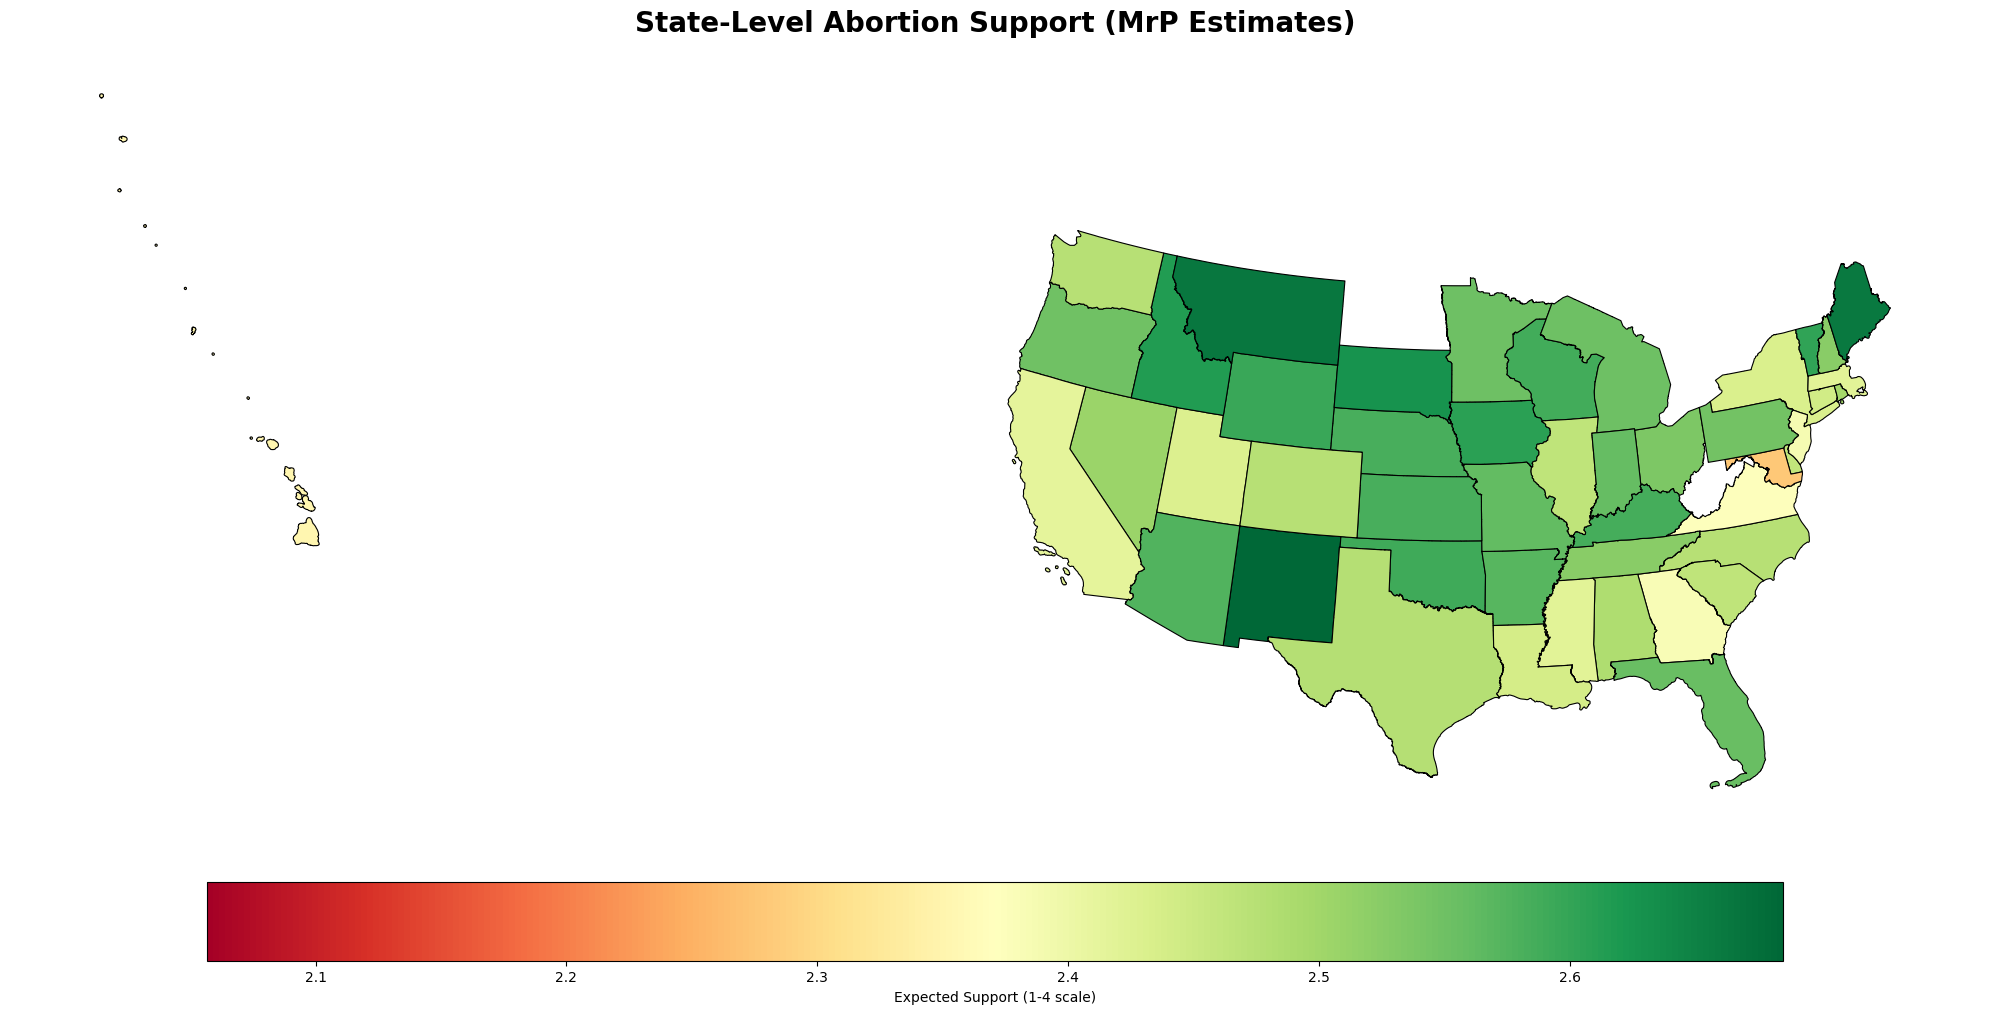

In [ ]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns


def generate_cell_predictions(fit, strat_frame, stan_data, batch_size=10000):
    # Generate predictions for stratification frame with mapped indices.

    # Extract posterior samples
    alpha = fit.stan_variable('alpha') 
    kappa = fit.stan_variable('kappa')
    eta_sex = fit.stan_variable('eta_sex')
    eta_age = fit.stan_variable('eta_age')
    eta_eth = fit.stan_variable('eta_eth')
    eta_income = fit.stan_variable('eta_income')
    eta_state = fit.stan_variable('eta_state')
    
    n_draws = alpha.shape[0] #Number of posterior samples
    n_cells = len(strat_frame) # Number of demographic cells in stratification frame
    K = stan_data['K'] #Number of Likert categories
    

    # Initialize result arrays
    pred_mean = np.zeros(n_cells)
    pred_median = np.zeros(n_cells)
    pred_lower = np.zeros(n_cells)
    pred_upper = np.zeros(n_cells)
    pred_sd = np.zeros(n_cells)
    prob_cats = np.zeros((n_cells, K))
    
    # Process in batches
    n_batches = int(np.ceil(n_cells / batch_size))
    print(f"\nProcessing {n_batches} batches...")
    
    for batch_idx in range(n_batches):
        start_idx = batch_idx * batch_size
        end_idx = min((batch_idx + 1) * batch_size, n_cells)
        batch_n = end_idx - start_idx
        
        print(f"  Batch {batch_idx+1}/{n_batches}: cells {start_idx:,} to {end_idx:,}")
        
        # Get batch data
        batch_data = strat_frame.iloc[start_idx:end_idx]
        
        # Calculate linear predictors for this batch
        mu_batch = np.zeros((batch_n, n_draws)) # for each cell in the strat frame, computing 4000 parallel predictions - one for each set of parameter values in the posterior distribution
        # μ = α + η_sex + η_age + η_ethnicity + η_income + η_state
        for i, (idx, row) in enumerate(batch_data.iterrows()):
            mu_batch[i, :] = (
                alpha +
                eta_sex[:, int(row['sex_idx']) - 1] +
                eta_age[:, int(row['age_idx']) - 1] +
                eta_eth[:, int(row['eth_idx']) - 1] +
                eta_income[:, int(row['income_idx']) - 1] +
                eta_state[:, int(row['state_idx']) - 1]
            )
        
        # Convert to probabilities(For EACH posterior sample j and EACH cell i)
        prob_batch = np.zeros((batch_n, n_draws, K))
        
        for k in range(K):
            if k == 0:
                prob_batch[:, :, k] = 1 / (1 + np.exp(-(kappa[:, 0] - mu_batch)))
            elif k == K - 1:
                prob_batch[:, :, k] = 1 - (1 / (1 + np.exp(-(kappa[:, K-2] - mu_batch))))
            else:
                upper = 1 / (1 + np.exp(-(kappa[:, k] - mu_batch)))
                lower = 1 / (1 + np.exp(-(kappa[:, k-1] - mu_batch)))
                prob_batch[:, :, k] = upper - lower
        
        # Calculate expected values(the weighted average of the Likert scale)
        categories = np.arange(1, K + 1)
        expected_y_batch = np.sum(prob_batch * categories[np.newaxis, np.newaxis, :], axis=2)
        
        # Store results
        pred_mean[start_idx:end_idx] = expected_y_batch.mean(axis=1)
        pred_median[start_idx:end_idx] = np.median(expected_y_batch, axis=1)
        pred_lower[start_idx:end_idx] = np.percentile(expected_y_batch, 2.5, axis=1)
        pred_upper[start_idx:end_idx] = np.percentile(expected_y_batch, 97.5, axis=1)
        pred_sd[start_idx:end_idx] = expected_y_batch.std(axis=1)
        
        for k in range(K):
            prob_cats[start_idx:end_idx, k] = prob_batch[:, :, k].mean(axis=1)
    
    # Add results to dataframe
    print("\nAdding results to stratification frame...")
    strat_frame['pred_mean'] = pred_mean
    strat_frame['pred_median'] = pred_median
    strat_frame['pred_lower'] = pred_lower
    strat_frame['pred_upper'] = pred_upper
    strat_frame['pred_sd'] = pred_sd
    
    for k in range(K):
        strat_frame[f'prob_cat_{k+1}'] = prob_cats[:, k]
    
    print(f"\n Cell-level predictions complete")
    print(f"  Prediction range: [{strat_frame['pred_mean'].min():.3f}, {strat_frame['pred_mean'].max():.3f}]")
    
    return strat_frame


# STATE-LEVEL AGGREGATION

def aggregate_to_state_level(strat_frame, state_col='state_simple', 
                              use_median_weights=False):

    if use_median_weights:
        print("\nUsing median population weights...")
        
        # Normalize weights within each state(converts absolute population counts to proportions that sum to 1)
        strat_frame['weight'] = strat_frame.groupby(state_col)['N_star.median'].transform(
            lambda x: x / x.sum()
        )
        
        # Weighted average within each state
        state_preds = strat_frame.groupby(state_col).apply(
            lambda x: pd.Series({
                'pred_mean': np.average(x['pred_mean'], weights=x['weight']),
                'pred_median': np.average(x['pred_median'], weights=x['weight']),
                'pred_lower': np.average(x['pred_lower'], weights=x['weight']),
                'pred_upper': np.average(x['pred_upper'], weights=x['weight']),
                'pred_sd': np.sqrt(np.average(x['pred_sd']**2, weights=x['weight'])),
                'n_cells': len(x),
                'total_pop': x['N_star.median'].sum(),
                # Category probabilities
                'prob_cat_1': np.average(x['prob_cat_1'], weights=x['weight']),
                'prob_cat_2': np.average(x['prob_cat_2'], weights=x['weight']),
                'prob_cat_3': np.average(x['prob_cat_3'], weights=x['weight']),
                'prob_cat_4': np.average(x['prob_cat_4'], weights=x['weight']),
            })
        ).reset_index()
        
    else:
        print("\nPropagating uncertainty from population weight samples...")
        
        # Get all N_star columns (excluding median)
        n_star_cols = [col for col in strat_frame.columns 
                      if col.startswith('N_star.') and col != 'N_star.median']
        
        print(f"  Using {len(n_star_cols)} population weight samples")
        
        state_results = []
        
        for state in strat_frame[state_col].unique():
            state_data = strat_frame[strat_frame[state_col] == state].copy()
            
            # For each population weight sample, compute weighted average
            state_preds_samples = []
            
            for n_col in n_star_cols:
                # Normalize weights
                weights = state_data[n_col] / state_data[n_col].sum()
                
                # Weighted average
                weighted_pred = np.average(state_data['pred_mean'], weights=weights)
                state_preds_samples.append(weighted_pred)
            
            # Summarize across weight samples
            state_results.append({
                state_col: state,
                'pred_mean': np.mean(state_preds_samples),
                'pred_median': np.median(state_preds_samples),
                'pred_lower': np.percentile(state_preds_samples, 2.5),
                'pred_upper': np.percentile(state_preds_samples, 97.5),
                'pred_sd': np.std(state_preds_samples),
                'n_cells': len(state_data),
                'total_pop': state_data['N_star.median'].sum()
            })
        
        state_preds = pd.DataFrame(state_results)
    
    print(f"\n State-level aggregation complete")
    print(f"  States: {len(state_preds)}")
    print(f"  Mean prediction range: [{state_preds['pred_mean'].min():.3f}, {state_preds['pred_mean'].max():.3f}]")
    
    return state_preds


# NATIONAL-LEVEL AGGREGATION

def aggregate_to_national_level(strat_frame, use_median_weights=False):
    
    if use_median_weights:
        # Normalize weights across entire nation
        total_pop = strat_frame['N_star.median'].sum()
        weights = strat_frame['N_star.median'] / total_pop
        
        national = {
            'pred_mean': np.average(strat_frame['pred_mean'], weights=weights),
            'pred_median': np.average(strat_frame['pred_median'], weights=weights),
            'pred_lower': np.average(strat_frame['pred_lower'], weights=weights),
            'pred_upper': np.average(strat_frame['pred_upper'], weights=weights),
            'pred_sd': np.sqrt(np.average(strat_frame['pred_sd']**2, weights=weights)),
            'total_cells': len(strat_frame),
            'total_pop': total_pop,
            'prob_cat_1': np.average(strat_frame['prob_cat_1'], weights=weights),
            'prob_cat_2': np.average(strat_frame['prob_cat_2'], weights=weights),
            'prob_cat_3': np.average(strat_frame['prob_cat_3'], weights=weights),
            'prob_cat_4': np.average(strat_frame['prob_cat_4'], weights=weights),
        }
        
    else:
        # Propagate uncertainty from population weights
        n_star_cols = [col for col in strat_frame.columns 
                      if col.startswith('N_star.') and col != 'N_star.median']
        
        national_samples = []
        
        for n_col in n_star_cols:
            total_pop = strat_frame[n_col].sum()
            weights = strat_frame[n_col] / total_pop
            weighted_pred = np.average(strat_frame['pred_mean'], weights=weights)
            national_samples.append(weighted_pred)
        
        national = {
            'pred_mean': np.mean(national_samples),
            'pred_median': np.median(national_samples),
            'pred_lower': np.percentile(national_samples, 2.5),
            'pred_upper': np.percentile(national_samples, 97.5),
            'pred_sd': np.std(national_samples),
            'total_cells': len(strat_frame),
            'total_pop': strat_frame['N_star.median'].sum()
        }
    
    print(f"\n✓ National estimate: {national['pred_mean']:.3f}")
    print(f"  95% CI: [{national['pred_lower']:.3f}, {national['pred_upper']:.3f}]")
    
    return national


# VISUALIZATION

def plot_mrp_results(state_preds, national_pred, shp_path, 
                     state_col='state_simple', output_prefix='mrp'):
    
    # Map
    print("\n1. Creating choropleth map...")
    fig_map = create_state_map(state_preds, shp_path, state_col, 
                                output_path=f'{output_prefix}_map.png')
    
    # Rankings
    print("2. Creating state rankings...")
    fig_rank = plot_state_rankings(state_preds, national_pred, state_col,
                                    output_path=f'{output_prefix}_rankings.png')
    
    # Distribution
    print("3. Creating distribution plot...")
    fig_dist = plot_prediction_distribution(state_preds, national_pred,
                                             output_path=f'{output_prefix}_distribution.png')
    
    print("\nAll visualizations saved")


def create_state_map(state_preds, shp_path, state_col, output_path):
    """Create choropleth map handling Alaska and territories properly."""
    # State name to abbreviation mapping
    state_name_to_abbr = {
        'alabama': 'AL', 'alaska': 'AK', 'arizona': 'AZ', 'arkansas': 'AR',
        'california': 'CA', 'colorado': 'CO', 'connecticut': 'CT', 'delaware': 'DE',
        'florida': 'FL', 'georgia': 'GA', 'hawaii': 'HI', 'idaho': 'ID',
        'illinois': 'IL', 'indiana': 'IN', 'iowa': 'IA', 'kansas': 'KS',
        'kentucky': 'KY', 'louisiana': 'LA', 'maine': 'ME', 'maryland': 'MD',
        'massachusetts': 'MA', 'michigan': 'MI', 'minnesota': 'MN', 'mississippi': 'MS',
        'missouri': 'MO', 'montana': 'MT', 'nebraska': 'NE', 'nevada': 'NV',
        'new hampshire': 'NH', 'new jersey': 'NJ', 'new mexico': 'NM', 'new york': 'NY',
        'north carolina': 'NC', 'north dakota': 'ND', 'ohio': 'OH', 'oklahoma': 'OK',
        'oregon': 'OR', 'pennsylvania': 'PA', 'rhode island': 'RI', 'south carolina': 'SC',
        'south dakota': 'SD', 'tennessee': 'TN', 'texas': 'TX', 'utah': 'UT',
        'vermont': 'VT', 'virginia': 'VA', 'washington': 'WA', 'west virginia': 'WV',
        'wisconsin': 'WI', 'wyoming': 'WY', 'district of columbia': 'DC'
    }
    
    shp = gpd.read_file(shp_path)
    shp['STATE'] = shp['STUSPS'].str.upper()
    
    # Remove US territories (keep 50 states + DC)
    territories = ['AS', 'GU', 'MP', 'PR', 'VI']
    shp = shp[~shp['STATE'].isin(territories)]
    
    # Map state names to abbreviations if needed
    state_preds = state_preds.copy()
    if state_preds[state_col].str.len().max() > 2:
        print("  Converting state names to abbreviations...")
        state_preds['STATE'] = state_preds[state_col].str.lower().map(state_name_to_abbr)
        unmapped = state_preds[state_preds['STATE'].isna()]
        if len(unmapped) > 0:
            print(f"  Warning: {len(unmapped)} states couldn't be mapped: {unmapped[state_col].unique()}")
    else:
        state_preds['STATE'] = state_preds[state_col].str.upper()
    
    plot_data = shp.merge(state_preds[['STATE', 'pred_mean', 'pred_lower', 'pred_upper']], 
                          on='STATE', how='inner')
    
    print(f"  Mapped {len(plot_data)} states for visualization")
    
    # Project to Albers Equal Area (handles Alaska crossing date line)
    plot_data = plot_data.to_crs('ESRI:102003')
    
    fig, ax = plt.subplots(figsize=(20, 12))
    
    plot_data.plot(
        column='pred_mean',
        ax=ax,
        legend=True,
        cmap='RdYlGn',
        edgecolor='black',
        linewidth=0.8,
        legend_kwds={'label': 'Expected Support (1-4 scale)',
                    'orientation': 'horizontal',
                    'shrink': 0.8,
                    'pad': 0.05},
        missing_kwds={'color': 'lightgrey'}
    )
    
    ax.set_title('State-Level Abortion Support (MrP Estimates)', 
                fontsize=20, fontweight='bold', pad=20)
    ax.axis('off')
    
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    print(f"  Map saved to {output_path}")
    plt.close()
    
    return fig


def plot_state_rankings(state_preds, national_pred, state_col, output_path, top_n=15):
    """Plot top and bottom states."""
    sorted_states = state_preds.sort_values('pred_mean', ascending=False)
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 10))
    
    # Top states
    top = sorted_states.head(top_n)
    y_pos = range(len(top))
    axes[0].barh(y_pos, top['pred_mean'], color='green', alpha=0.7)
    axes[0].errorbar(top['pred_mean'], y_pos,
                     xerr=[top['pred_mean']-top['pred_lower'], 
                           top['pred_upper']-top['pred_mean']],
                     fmt='none', color='black', capsize=3)
    axes[0].set_yticks(y_pos)
    axes[0].set_yticklabels(top[state_col])
    axes[0].invert_yaxis()
    axes[0].set_xlabel('Support (1-4 scale)')
    axes[0].set_title(f'Top {top_n} States', fontweight='bold')
    axes[0].axvline(national_pred['pred_mean'], color='red', 
                   linestyle='--', linewidth=2, label='National')
    axes[0].legend()
    axes[0].grid(axis='x', alpha=0.3)
    
    # Bottom states
    bottom = sorted_states.tail(top_n)
    y_pos = range(len(bottom))
    axes[1].barh(y_pos, bottom['pred_mean'], color='red', alpha=0.7)
    axes[1].errorbar(bottom['pred_mean'], y_pos,
                     xerr=[bottom['pred_mean']-bottom['pred_lower'],
                           bottom['pred_upper']-bottom['pred_mean']],
                     fmt='none', color='black', capsize=3)
    axes[1].set_yticks(y_pos)
    axes[1].set_yticklabels(bottom[state_col])
    axes[1].invert_yaxis()
    axes[1].set_xlabel('Support (1-4 scale)')
    axes[1].set_title(f'Bottom {top_n} States', fontweight='bold')
    axes[1].axvline(national_pred['pred_mean'], color='red',
                   linestyle='--', linewidth=2, label='National')
    axes[1].legend()
    axes[1].grid(axis='x', alpha=0.3)
    
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    plt.close()
    
    return fig


def plot_prediction_distribution(state_preds, national_pred, output_path):
    """Plot distribution of state predictions."""
    fig, ax = plt.subplots(figsize=(12, 6))
    
    ax.hist(state_preds['pred_mean'], bins=20, 
           color='steelblue', alpha=0.7, edgecolor='black')
    ax.axvline(national_pred['pred_mean'], color='red', 
              linestyle='--', linewidth=3, label='National Estimate')
    ax.set_xlabel('Predicted Support (1-4 scale)', fontsize=14)
    ax.set_ylabel('Number of States', fontsize=14)
    ax.set_title('Distribution of State-Level Predictions', 
                fontsize=16, fontweight='bold')
    ax.legend(fontsize=12)
    ax.grid(axis='y', alpha=0.3)
    
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    plt.close()
    
    return fig


# ============================================================
# COMPLETE WORKFLOW
# ============================================================

if __name__ == "__main__":

    
    # Example usage:
    # strat_frame = pd.read_csv("your_mapped_stratification_frame.csv")
    
    # Step 1: Generate cell-level predictions
    strat_frame = generate_cell_predictions(fit, strat_frame, stan_data)
    
    # Step 2: Aggregate to state level
    state_preds = aggregate_to_state_level(strat_frame, 
                                           state_col='state_simple',
                                           use_median_weights=False)
    
    # Step 3: Aggregate to national level
    national_pred = aggregate_to_national_level(strat_frame,
                                                use_median_weights=False)
    
    # Step 4: Create visualizations
    shp_path = "/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/tl_2025_us_state/tl_2025_us_state.shp"
    plot_mrp_results(state_preds, national_pred, shp_path,
                    state_col='state_simple', output_prefix='/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_n_abortion/abortion_mrp')
    
    # Step 5: Save results
    state_preds.to_csv('/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_n_abortion/state_level_predictions.csv', index=False)
    strat_frame.to_csv('/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_n_abortion/cell_level_predictions.csv', index=False)
    
    pd.DataFrame([national_pred]).to_csv('/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_n_abortion/national_prediction.csv', index=False)
   
    print("\n" + "="*70)
    print("MrP ANALYSIS COMPLETE")
    print("="*70)
    print("\nOutputs:")
    print("  - state_level_predictions.csv")
    print("  - cell_level_predictions.csv")
    print("  - national_prediction.csv")
    print("  - abortion_mrp_map.png")
    print("  - abortion_mrp_rankings.png")
    print("  - abortion_mrp_distribution.png")


In [30]:
    shp_path = "/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/tl_2025_us_state/tl_2025_us_state.shp"
    plot_mrp_results(state_preds, national_pred, shp_path,
                    state_col='state_simple', output_prefix='/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_n_abortion/abortion_mrp')
    
    # Step 5: Save results
    state_preds.to_csv('/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_n_abortion/state_level_predictions.csv', index=False)
    strat_frame.to_csv('/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_n_abortion/cell_level_predictions.csv', index=False)
    
    pd.DataFrame([national_pred]).to_csv('/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_n_abortion/national_prediction.csv', index=False)
   


CREATING VISUALIZATIONS

1. Creating choropleth map...
  Converting state names to abbreviations...
  Mapped 48 states for visualization
  ✓ Map saved to /mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_n_abortion/abortion_mrp_map.png
2. Creating state rankings...
3. Creating distribution plot...

✓ All visualizations saved


Aggregating probabilities with full uncertainty propagation...
  Using 104 N_star samples
  Probability columns: ['prob_cat_1', 'prob_cat_2', 'prob_cat_3', 'prob_cat_4']
✓ Aggregated 48 states with uncertainty
  Mean probability sum: 1.0000 (should be ~1.0)

Columns in state_probs:
['state_simple', 'prob_cat_1', 'prob_cat_1_lower', 'prob_cat_1_upper', 'prob_cat_2', 'prob_cat_2_lower', 'prob_cat_2_upper', 'prob_cat_3', 'prob_cat_3_lower', 'prob_cat_3_upper', 'prob_cat_4', 'prob_cat_4_lower', 'prob_cat_4_upper']
✓ Categorical probability maps saved to /mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_n_abortion/abortion_mrp_probabilities.png


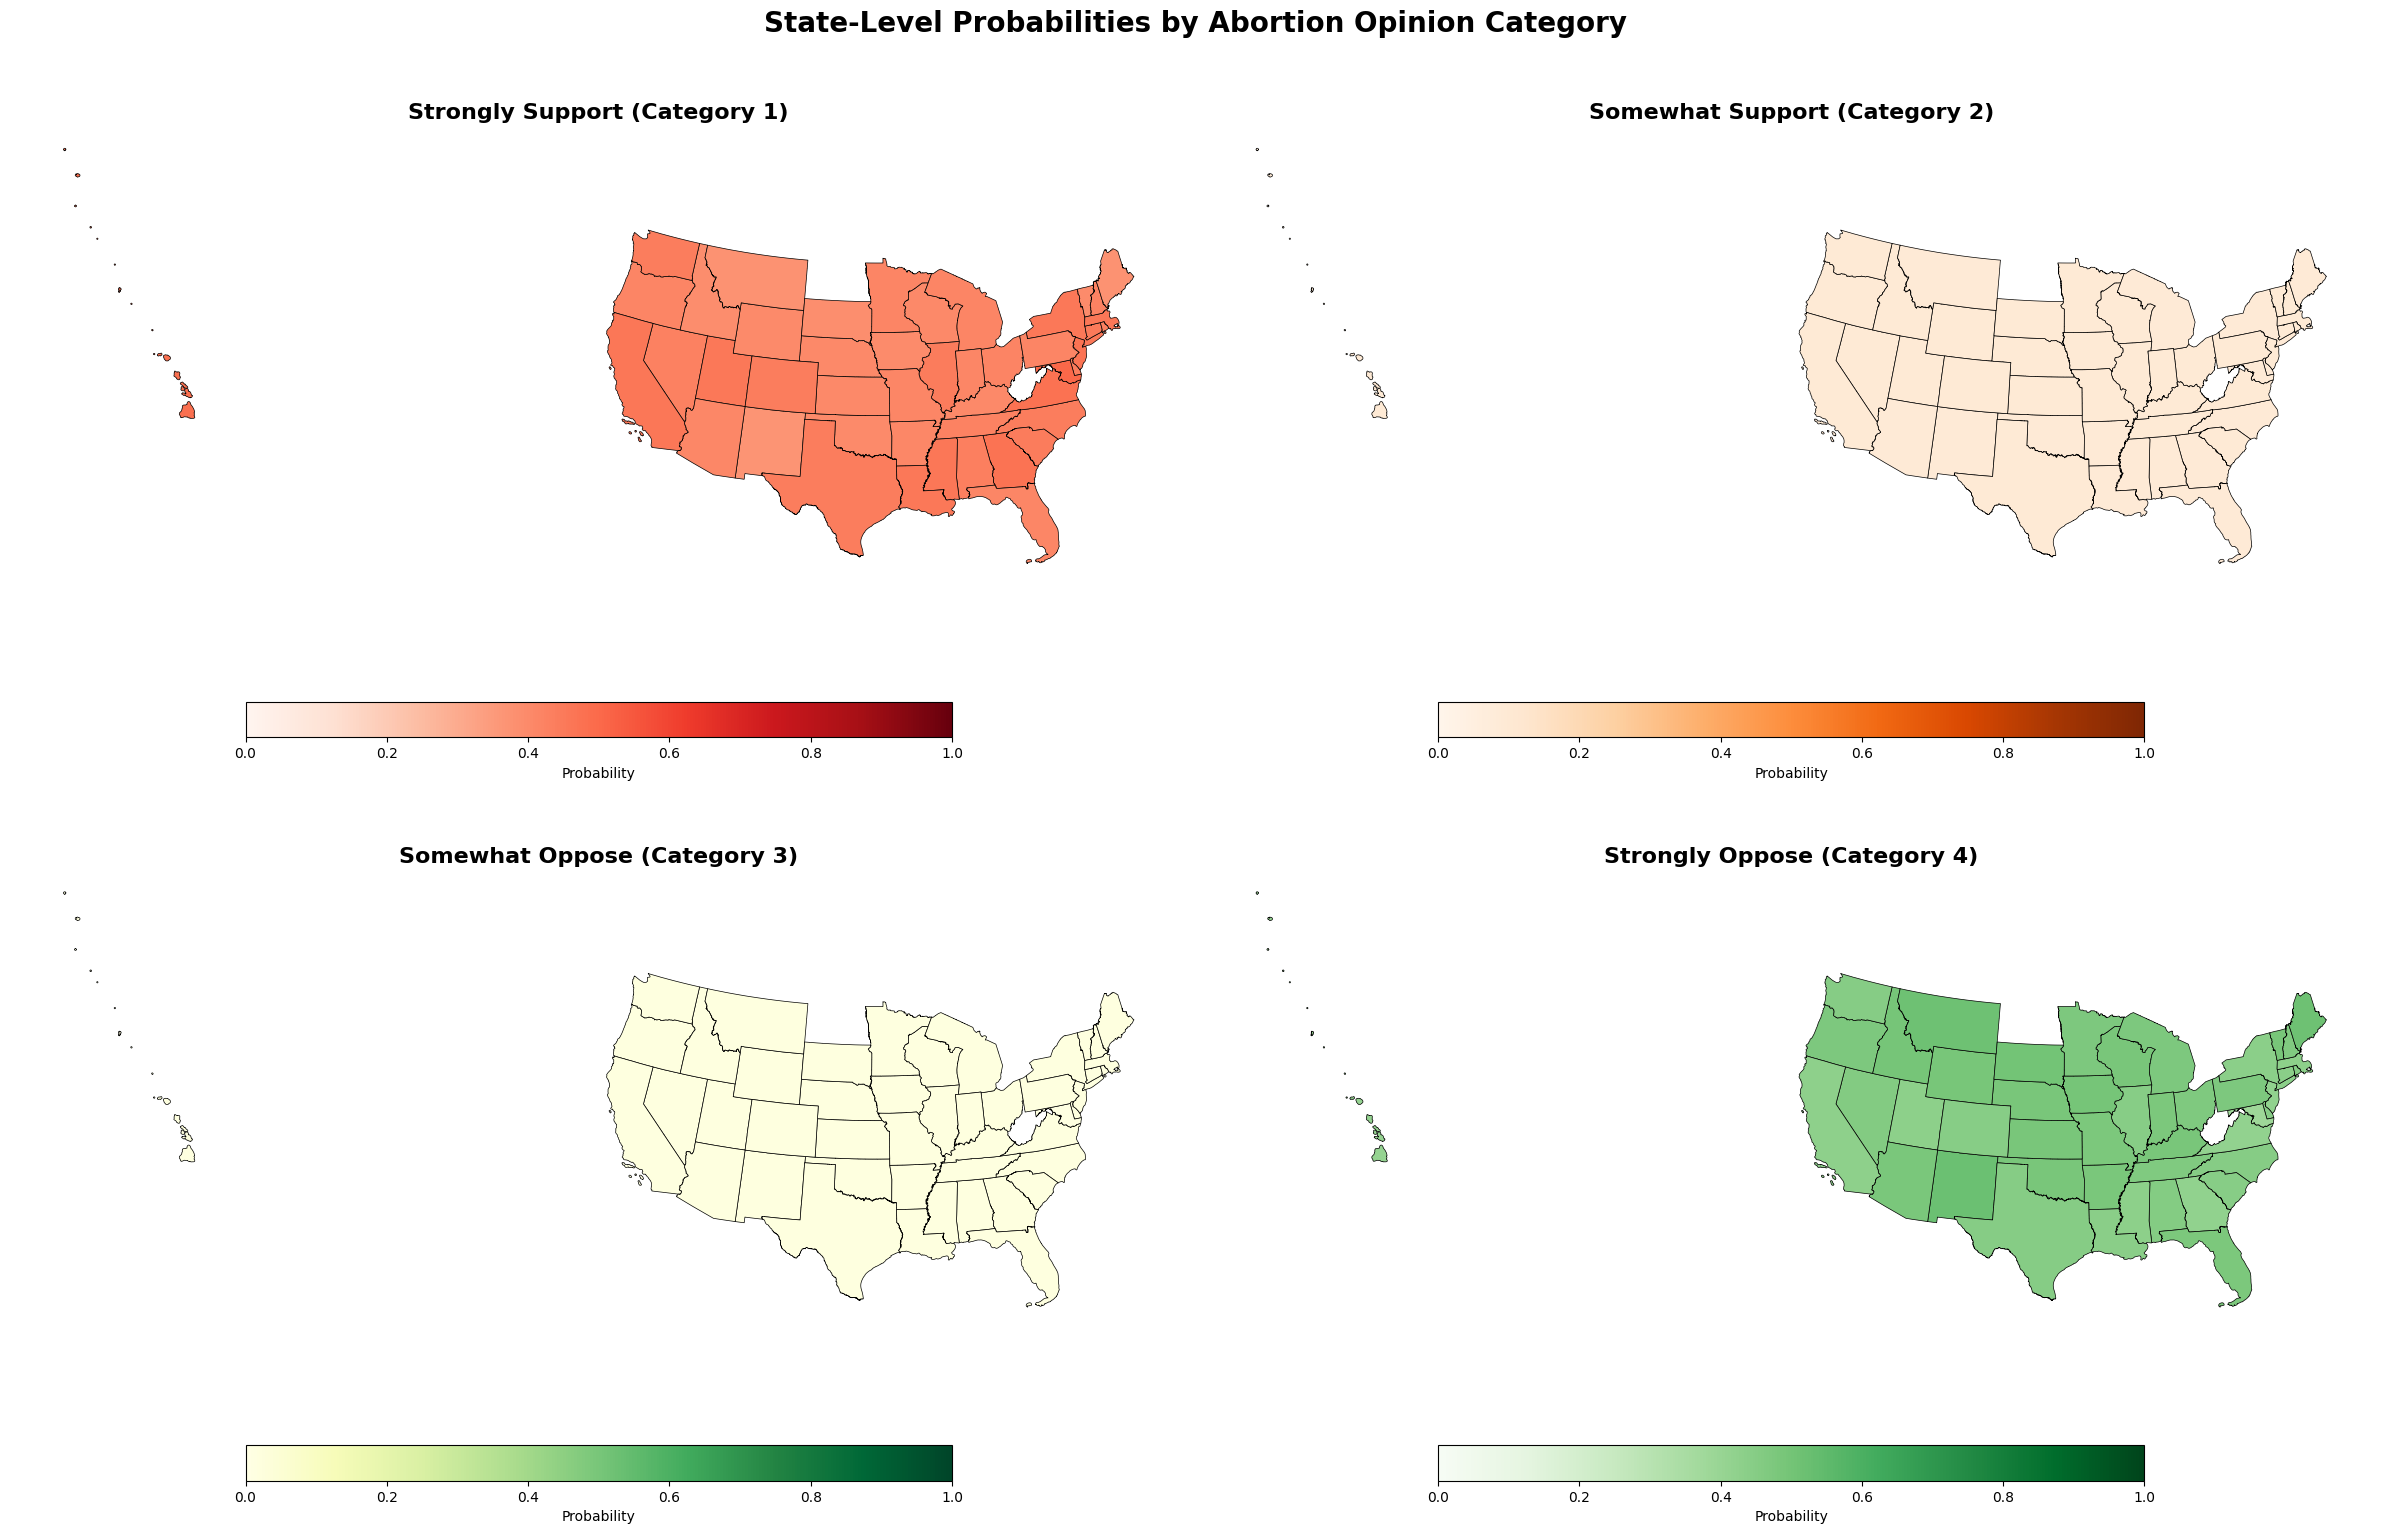

✓ Dominant category map saved to abortion_dominant_category.png


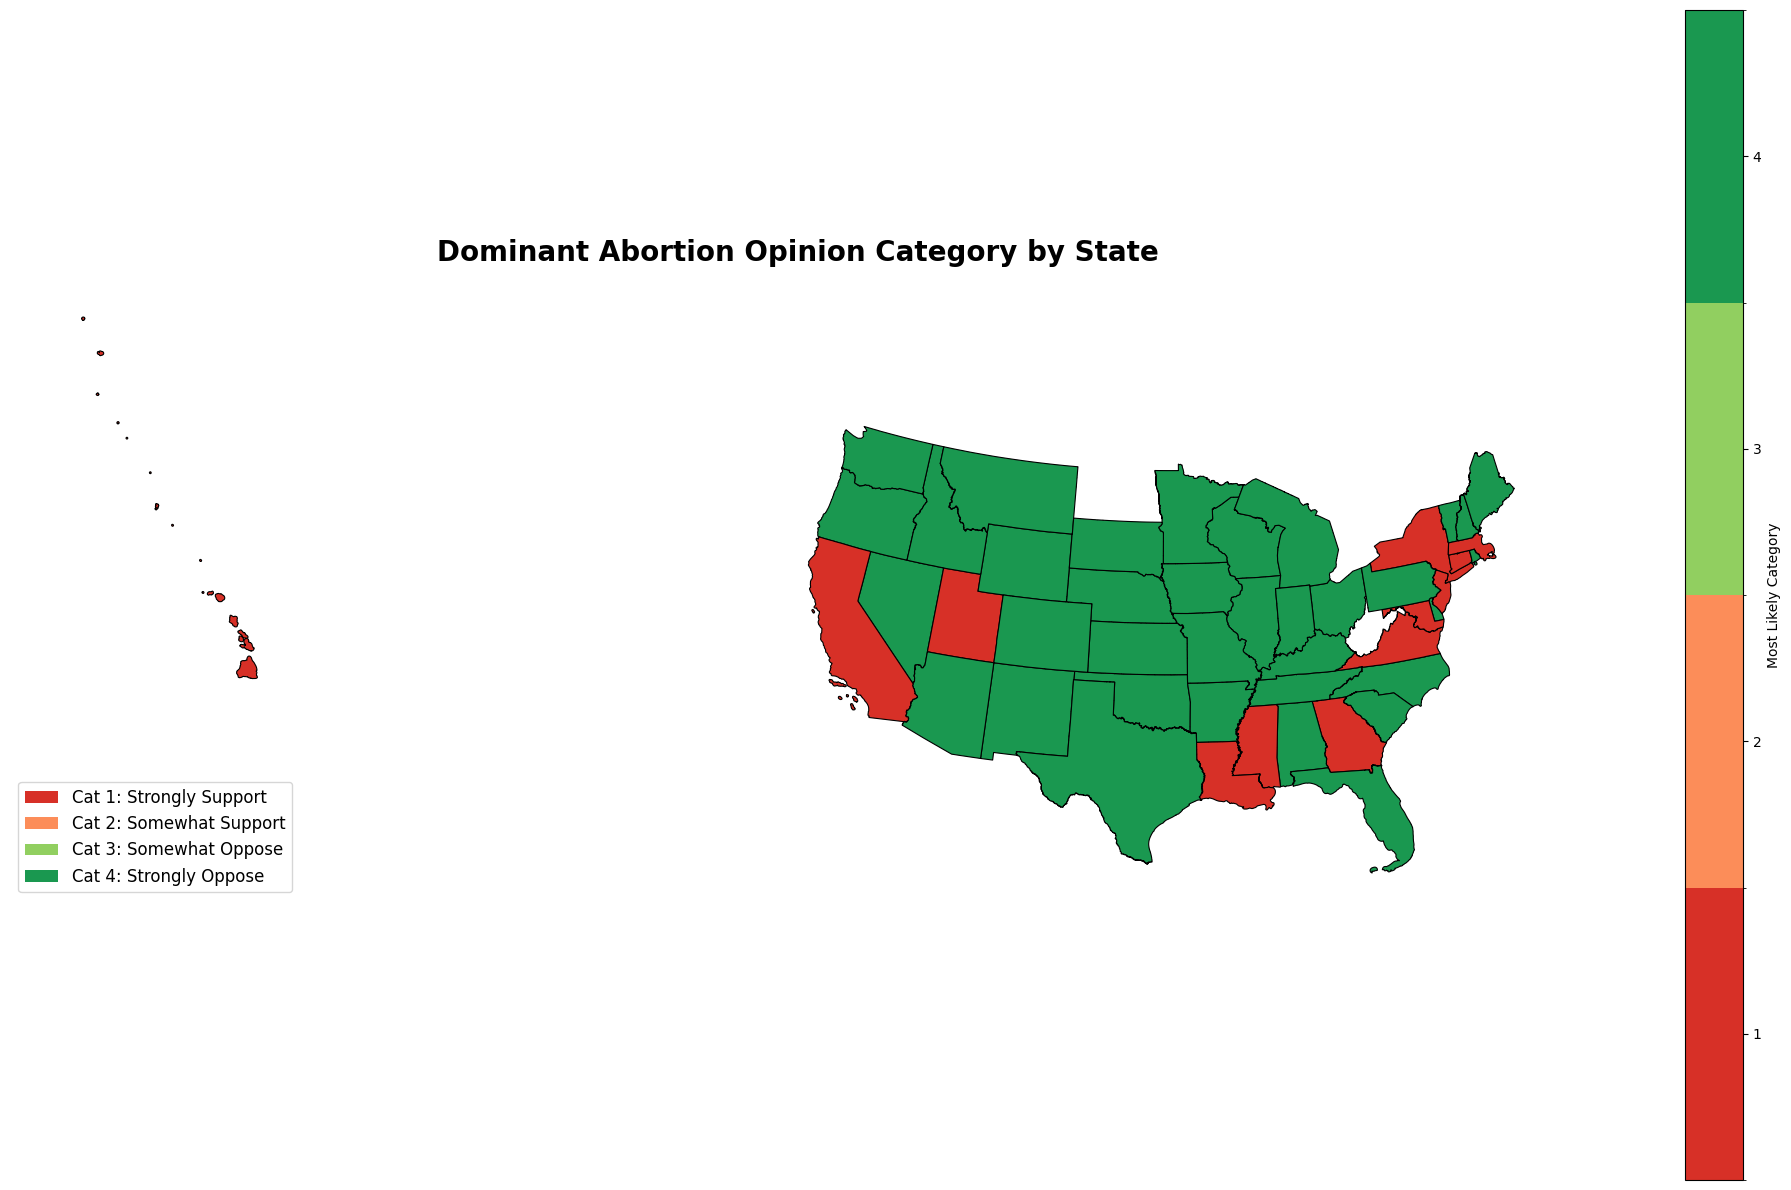


Dominant category by state:
  Category 1: 13 states
  Category 2: 0 states
    []
  Category 3: 0 states
    []
  Category 4: 35 states


In [ ]:
def aggregate_probabilities_with_uncertainty(strat_frame, state_col='state_simple'):
    """
    Aggregate probabilities using all N_star samples for full uncertainty.
    """
    print("Aggregating probabilities with full uncertainty propagation...")
    
    # Find N_star columns and probability columns
    n_star_cols = [col for col in strat_frame.columns 
                   if col.startswith('N_star.') and col != 'N_star.median']
    prob_cols = [col for col in strat_frame.columns if col.startswith('prob_cat_')]
    
    print(f"  Using {len(n_star_cols)} N_star samples")
    print(f"  Probability columns: {prob_cols}")
    
    state_results = []
    
    for state in strat_frame[state_col].unique():
        state_data = strat_frame[strat_frame[state_col] == state].copy()
        
        # For each N_star sample, compute weighted probabilities
        prob_samples = {prob_col: [] for prob_col in prob_cols}
        
        for n_col in n_star_cols:
            # Normalize weights for this sample
            weights = state_data[n_col] / state_data[n_col].sum()
            
            # Weighted average of each probability
            for prob_col in prob_cols:
                weighted_prob = np.average(state_data[prob_col], weights=weights)
                prob_samples[prob_col].append(weighted_prob)
        
        # Summarize: mean across all N_star samples
        result = {state_col: state}
        for prob_col in prob_cols:
            result[prob_col] = np.mean(prob_samples[prob_col])
            result[f'{prob_col}_lower'] = np.percentile(prob_samples[prob_col], 2.5)
            result[f'{prob_col}_upper'] = np.percentile(prob_samples[prob_col], 97.5)
        
        state_results.append(result)
    
    state_probs = pd.DataFrame(state_results)
    
    print(f"Aggregated {len(state_probs)} states with uncertainty")
    
    # Verify probabilities sum to ~1
    prob_sum = state_probs[prob_cols].sum(axis=1)
    print(f"  Mean probability sum: {prob_sum.mean():.4f} (should be ~1.0)")
    
    return state_probs

state_probs = aggregate_probabilities_with_uncertainty(strat_frame, 'state_simple')

print("\nColumns in state_probs:")
print(state_probs.columns.tolist())

plot_categorical_probabilities(state_probs, shp_path, 'state_simple')
plot_dominant_category(state_probs, shp_path, 'state_simple')

In [ ]:
def plot_categorical_probabilities(state_preds, shp_path, state_col, output_prefix='/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_n_abortion/abortion_mrp'):

    # State name to abbreviation mapping
    state_name_to_abbr = {
        'alabama': 'AL', 'alaska': 'AK', 'arizona': 'AZ', 'arkansas': 'AR',
        'california': 'CA', 'colorado': 'CO', 'connecticut': 'CT', 'delaware': 'DE',
        'florida': 'FL', 'georgia': 'GA', 'hawaii': 'HI', 'idaho': 'ID',
        'illinois': 'IL', 'indiana': 'IN', 'iowa': 'IA', 'kansas': 'KS',
        'kentucky': 'KY', 'louisiana': 'LA', 'maine': 'ME', 'maryland': 'MD',
        'massachusetts': 'MA', 'michigan': 'MI', 'minnesota': 'MN', 'mississippi': 'MS',
        'missouri': 'MO', 'montana': 'MT', 'nebraska': 'NE', 'nevada': 'NV',
        'new hampshire': 'NH', 'new jersey': 'NJ', 'new mexico': 'NM', 'new york': 'NY',
        'north carolina': 'NC', 'north dakota': 'ND', 'ohio': 'OH', 'oklahoma': 'OK',
        'oregon': 'OR', 'pennsylvania': 'PA', 'rhode island': 'RI', 'south carolina': 'SC',
        'south dakota': 'SD', 'tennessee': 'TN', 'texas': 'TX', 'utah': 'UT',
        'vermont': 'VT', 'virginia': 'VA', 'washington': 'WA', 'west virginia': 'WV',
        'wisconsin': 'WI', 'wyoming': 'WY', 'district of columbia': 'DC'
    }
    
    shp = gpd.read_file(shp_path)
    shp['STATE'] = shp['STUSPS'].str.upper()
    territories = ['AS', 'GU', 'MP', 'PR', 'VI']
    shp = shp[~shp['STATE'].isin(territories)]
    
    # Map state names
    state_preds = state_preds.copy()
    if state_preds[state_col].str.len().max() > 2:
        state_preds['STATE'] = state_preds[state_col].str.lower().map(state_name_to_abbr)
    else:
        state_preds['STATE'] = state_preds[state_col].str.upper()
    
    # Merge
    plot_data = shp.merge(state_preds[['STATE', 'prob_cat_1', 'prob_cat_2', 
                                       'prob_cat_3', 'prob_cat_4']], 
                          on='STATE', how='inner')
    plot_data = plot_data.to_crs('ESRI:102003')
    
    # Create 2x2 subplot
    fig, axes = plt.subplots(2, 2, figsize=(24, 16))
    
    categories = [
        ('prob_cat_1', 'Strongly Support (Category 1)', 'Reds', axes[0, 0]),
        ('prob_cat_2', 'Somewhat Support (Category 2)', 'Oranges', axes[0, 1]),
        ('prob_cat_3', 'Somewhat Oppose (Category 3)', 'YlGn', axes[1, 0]),
        ('prob_cat_4', 'Strongly Oppose (Category 4)', 'Greens', axes[1, 1])
    ]
    
    for prob_col, title, cmap, ax in categories:
        plot_data.plot(
            column=prob_col,
            ax=ax,
            legend=True,
            cmap=cmap,
            edgecolor='black',
            linewidth=0.5,
            vmin=0,
            vmax=1,
            legend_kwds={'label': 'Probability',
                        'orientation': 'horizontal',
                        'shrink': 0.6}
        )
        ax.set_title(title, fontsize=16, fontweight='bold')
        ax.axis('off')
    
    plt.suptitle('State-Level Probabilities by Abortion Opinion Category', 
                 fontsize=20, fontweight='bold', y=0.98)
    plt.tight_layout()
    plt.savefig(f'{output_prefix}_probabilities.png', dpi=300, bbox_inches='tight')
    print(f"Categorical probability maps saved to {output_prefix}_probabilities.png")
    plt.show()


def plot_dominant_category(state_preds, shp_path, state_col, output_path='abortion_dominant_category.png'):
    state_name_to_abbr = {
        'alabama': 'AL', 'alaska': 'AK', 'arizona': 'AZ', 'arkansas': 'AR',
        'california': 'CA', 'colorado': 'CO', 'connecticut': 'CT', 'delaware': 'DE',
        'florida': 'FL', 'georgia': 'GA', 'hawaii': 'HI', 'idaho': 'ID',
        'illinois': 'IL', 'indiana': 'IN', 'iowa': 'IA', 'kansas': 'KS',
        'kentucky': 'KY', 'louisiana': 'LA', 'maine': 'ME', 'maryland': 'MD',
        'massachusetts': 'MA', 'michigan': 'MI', 'minnesota': 'MN', 'mississippi': 'MS',
        'missouri': 'MO', 'montana': 'MT', 'nebraska': 'NE', 'nevada': 'NV',
        'new hampshire': 'NH', 'new jersey': 'NJ', 'new mexico': 'NM', 'new york': 'NY',
        'north carolina': 'NC', 'north dakota': 'ND', 'ohio': 'OH', 'oklahoma': 'OK',
        'oregon': 'OR', 'pennsylvania': 'PA', 'rhode island': 'RI', 'south carolina': 'SC',
        'south dakota': 'SD', 'tennessee': 'TN', 'texas': 'TX', 'utah': 'UT',
        'vermont': 'VT', 'virginia': 'VA', 'washington': 'WA', 'west virginia': 'WV',
        'wisconsin': 'WI', 'wyoming': 'WY', 'district of columbia': 'DC'
    }
    
    shp = gpd.read_file(shp_path)
    shp['STATE'] = shp['STUSPS'].str.upper()
    territories = ['AS', 'GU', 'MP', 'PR', 'VI']
    shp = shp[~shp['STATE'].isin(territories)]
    
    state_preds = state_preds.copy()
    if state_preds[state_col].str.len().max() > 2:
        state_preds['STATE'] = state_preds[state_col].str.lower().map(state_name_to_abbr)
    else:
        state_preds['STATE'] = state_preds[state_col].str.upper()
    
    # Find dominant category
    prob_cols = ['prob_cat_1', 'prob_cat_2', 'prob_cat_3', 'prob_cat_4']
    state_preds['dominant_cat'] = state_preds[prob_cols].idxmax(axis=1).str.replace('prob_cat_', '').astype(int)
    state_preds['dominant_prob'] = state_preds[prob_cols].max(axis=1)
    
    # Merge
    plot_data = shp.merge(state_preds[['STATE', 'dominant_cat', 'dominant_prob']], 
                          on='STATE', how='inner')
    plot_data = plot_data.to_crs('ESRI:102003')
    
    # Create map
    fig, ax = plt.subplots(figsize=(20, 12))
    
    import matplotlib.colors as mcolors
    colors = ['#d73027', '#fc8d59', '#91cf60', '#1a9850']  
    cmap = mcolors.ListedColormap(colors)
    bounds = [0.5, 1.5, 2.5, 3.5, 4.5]
    norm = mcolors.BoundaryNorm(bounds, cmap.N)
    
    plot_data.plot(
        column='dominant_cat',
        ax=ax,
        legend=True,
        cmap=cmap,
        norm=norm,
        edgecolor='black',
        linewidth=0.8,
        legend_kwds={'label': 'Most Likely Category',
                    'ticks': [1, 2, 3, 4]}
    )
    
    ax.set_title('Dominant Abortion Opinion Category by State', 
                fontsize=20, fontweight='bold', pad=20)
    ax.axis('off')
    
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor=colors[0], label='Cat 1: Strongly Support'),
        Patch(facecolor=colors[1], label='Cat 2: Somewhat Support'),
        Patch(facecolor=colors[2], label='Cat 3: Somewhat Oppose'),
        Patch(facecolor=colors[3], label='Cat 4: Strongly Oppose')
    ]
    ax.legend(handles=legend_elements, loc='lower left', fontsize=12)
    
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    print(f"Dominant category map saved to {output_path}")
    plt.show()
    
    print("\nDominant category by state:")
    for cat in [1, 2, 3, 4]:
        n_states = (state_preds['dominant_cat'] == cat).sum()
        states = state_preds[state_preds['dominant_cat'] == cat][state_col].tolist()
        print(f"  Category {cat}: {n_states} states")
        if n_states <= 10:
            print(f"    {states}")


In [32]:
state_preds

,state_simple,pred_mean,pred_median,pred_lower,pred_upper,pred_sd,n_cells,total_pop
0,Alabama,2.485107,2.485107,2.485012,2.485209,0.000049,25308,1.604706e+05
1,Arizona,2.576295,2.576295,2.576265,2.576323,0.000015,25920,2.184829e+05
2,Arkansas,2.570916,2.570920,2.570874,2.570949,0.000021,24948,9.849387e+04
3,California,2.413104,2.413105,2.413067,2.413138,0.000018,25920,1.149943e+06
4,Colorado,2.474605,2.474604,2.474581,2.474631,0.000014,25740,1.795238e+05
5,Connecticut,2.443636,2.443638,2.443583,2.443704,0.000033,24444,1.104426e+05
6,Delaware,2.463946,2.463952,2.463826,2.464063,0.000062,23256,2.833995e+04
7,District of Columbia,2.056717,2.056698,2.056535,2.056916,0.000114,21564,2.147349e+04
8,Florida,2.556768,2.556768,2.556724,2.556814,0.000024,25848,6.617472e+05
9,Georgia,2.381372,2.381368,2.381298,2.381470,0.000043,25524,3.174816e+05


In [33]:
strat_frame

,Unnamed: 0.1,Unnamed: 0,state_abbreviation,state_simple,state_electoral.college,region,gender,ethnicity,age_bins,college_grad,...,pred_mean,pred_median,pred_lower,pred_upper,pred_sd,prob_cat_1,prob_cat_2,prob_cat_3,prob_cat_4,weight
0,0,0,AL,Alabama,Alabama,South,M,Black,6.65+,Does not have a College Degree,...,2.755016,2.755831,2.532855,2.970851,0.110994,0.339467,0.103968,0.018648,0.537917,1.102617e-03
1,1,1,AL,Alabama,Alabama,South,F,White,2.25-34,Has a College Degree,...,2.316432,2.315452,2.214994,2.419129,0.052108,0.482446,0.109045,0.018139,0.390370,9.113285e-05
2,2,2,AL,Alabama,Alabama,South,M,Hispanic,3.35-44,Does not have a College Degree,...,2.614919,2.613642,2.448284,2.788232,0.087221,0.383618,0.107683,0.018861,0.489838,2.949123e-05
3,3,3,AL,Alabama,Alabama,South,F,White,4.45-54,Does not have a College Degree,...,2.229708,2.229599,2.127286,2.336361,0.053412,0.512420,0.107693,0.017645,0.362242,1.180266e-04
4,4,4,AL,Alabama,Alabama,South,F,Black,3.35-44,Does not have a College Degree,...,1.743434,1.741099,1.627054,1.872447,0.062016,0.690994,0.085369,0.012844,0.210792,2.934271e-04
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1233535,1233535,1299523,WY,Wyoming,Wyoming,West,F,Native,1.18-24,Has a College Degree,...,2.166790,2.097850,1.499664,3.207745,0.435797,0.541368,0.096674,0.015759,0.346200,2.164008e-05
1233536,1233536,1299524,WY,Wyoming,Wyoming,West,F,Black,1.18-24,Does not have a College Degree,...,1.405237,1.403697,1.319257,1.501543,0.046388,0.825995,0.054526,0.007725,0.111754,4.130347e-05
1233537,1233537,1299525,WY,Wyoming,Wyoming,West,M,Mixed-race,6.65+,Has a College Degree,...,3.061320,3.063525,2.864956,3.239740,0.095817,0.247071,0.090214,0.017038,0.645676,5.721610e-07
1233538,1233538,1299526,WY,Wyoming,Wyoming,West,F,Asian,6.65+,Has a College Degree,...,2.090831,2.086760,1.862687,2.337906,0.122115,0.562029,0.103276,0.016530,0.318165,6.834941e-06
